# Supergranulation 2021 (PIC): quality of the HARPS-N exposures

The results of `PIC/supergranulation.py` for 2021-05-01 to 2021-08-01 (`local_path('supergranulation_results')`: the folder with `days/` and `results/`), compared again with HARPS-N **without the exposures of poor quality**.

The public release of the HARPS-N solar telescope has two quality flags for every exposure:

| column | meaning |
|---|---|
| `data_quality` | 0 / 1: 1 = the reduction is good (0: e.g. a problem with the instrument or the reduction) |
| `obs_quality` | 0 to 1: the quality of the sky during the exposure (clouds, from the exposure meter / pyrheliometer); the release only has exposures with `obs_quality` ≥ 0.9 |

The exposures with `data_quality` = 0 are always left out (there are none in this period), and those with `obs_quality` < `MIN_OBS_QUALITY` (0.99, a usual cut for the HARPS-N solar data) are left out of the comparison, and then also the days with fewer than `MIN_DAY_EXP` (50) exposures left. Everything else is the `collect` step of `PIC/supergranulation.py` (calibration of the HMI velocities with all the epochs, p modes, simulations of every exposure, comparisons), run here on the products downloaded from PIC: `collect --harpsn ... --min-obs-quality ... --min-day-exp ...` does the same on PIC. The release also gives the airmass of every exposure (section 5.1).

In [1]:
import os, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from argparse import Namespace
from IPython.display import Image, display
from sunsim import local_path

OUT = str(local_path('supergranulation_results'))           # days/ and results/ of PIC/supergranulation.py
START = '2021-05-01'
N_RINGS = 30
MIN_OBS_QUALITY = 0.99                                      # exposures with a lower obs_quality are left out
MIN_DAY_EXP = 50                                            # then also the days with fewer exposures left are left out
SCAN = [0.95, 0.98, 0.99, 0.995, 0.998]                     # thresholds of the scan (section 4)
HARPSN = str(local_path('harpsn_sun'))

spec = importlib.util.spec_from_file_location('sg_pic', os.path.join('..', 'PIC', 'supergranulation.py'))
sgp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sgp)

def collect(results, min_obs_quality=None, figures=True, min_day_exp=0):
    """The collect step of PIC/supergranulation.py on the products of OUT, results in OUT/<results>."""
    a = Namespace(out=OUT, start=START, conf=os.path.join('..', 'conf', 'starsim_sun_sdo_mps_highres.conf'),
                  mps_folder=str(local_path('muram_spectra')), mask=str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'),
                  interventions=str(local_path('harpsn_interventions')), n_rings=N_RINGS, vr_degree=2, ref_window=1800.0,
                  min_exp=5, harpsn=HARPSN, min_obs_quality=min_obs_quality, min_day_exp=min_day_exp,
                  results=results, figures=figures)
    backend = plt.get_backend()
    try:
        sgp.run_collect(a)                                  # it switches matplotlib to Agg (files only)
    finally:
        plt.switch_backend(backend)                         # also if it fails: else the figures are not shown
    return os.path.join(OUT, results)

def table(results, name):
    return pd.read_csv(os.path.join(OUT, results, name))
print('results of PIC in', OUT)

results of PIC in /Users/sophiestucki/Downloads/supergranulation_2021-05-01_2021-08-01


## 1. The quality flags of the exposures

Every exposure of the days done on PIC (with an HMI epoch) and its flags in the release (matched by the start of the exposure in `file_root`).

In [2]:
ex, ep, frames = sgp.load_days(OUT, N_RINGS)
qf = sgp.exposure_quality(ex, HARPSN)
oq, dq = qf['obs_quality'], qf['data_quality']
hour = (ex['jd'] + 0.5) % 1 * 24                           # UTC
print('%d exposures on %d days; not in the release: %d; data_quality = 0: %d' % (len(oq), len(np.unique(ex['day'])),
      np.isnan(oq).sum(), np.sum(dq == 0)))
pd.DataFrame({'obs_quality <': SCAN, 'exposures left out': [int(np.sum(oq < q)) for q in SCAN],
              '%': [100 * np.mean(oq < q) for q in SCAN]}).round(1)

2008 exposures on 38 days; not in the release: 0; data_quality = 0: 0


,obs_quality <,exposures left out,%
0,1.0,53,2.6
1,1.0,201,10.0
2,1.0,345,17.2
3,1.0,515,25.6
4,1.0,802,39.9


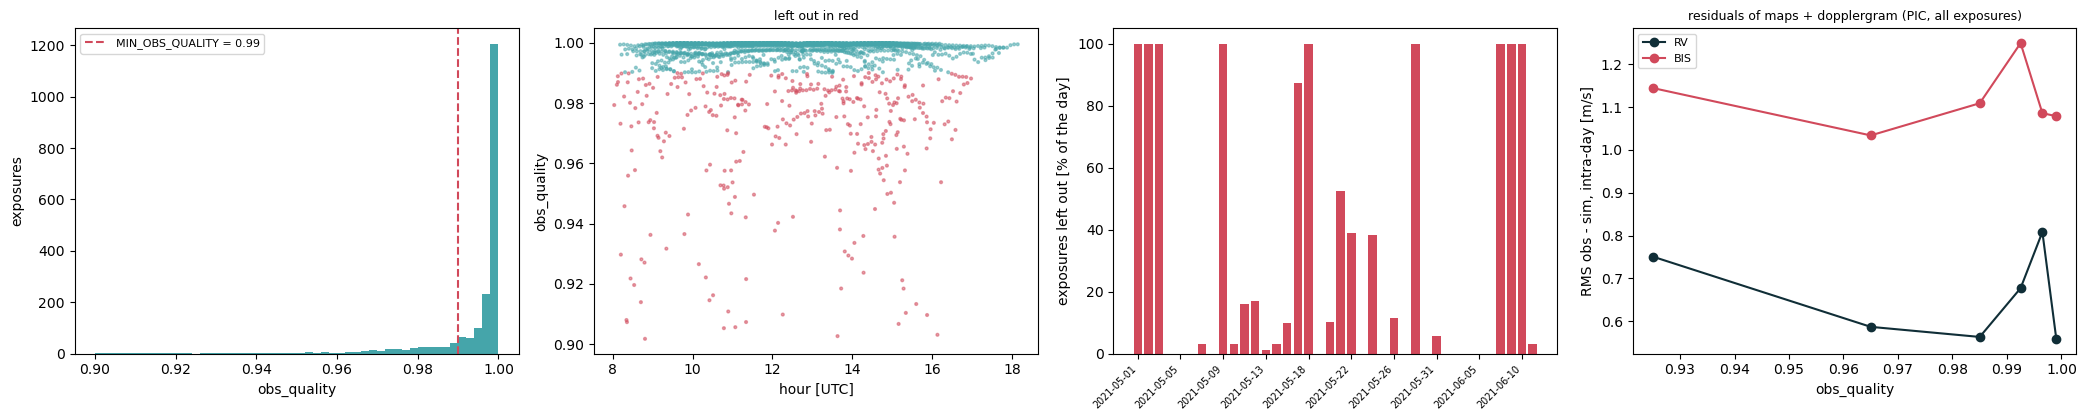

In [3]:
# the residuals of the PIC comparison (all the exposures; median of every day removed) against obs_quality
pic = table('results', 'exposures.csv')
q_of = dict(zip(np.round(ex['jd'] * 86400).astype(np.int64), oq))
pic['obs_quality'] = [q_of.get(k, np.nan) for k in np.round(pic['jd_utc'] * 86400).astype(np.int64)]
MODEL = 'maps_dopplergram'
def intra(col):
    return pic[col] - pic.groupby('day')[col].transform('median')

fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
ax = axes[0]
ax.hist(oq, bins=np.linspace(0.9, 1, 51), color='#45a5aa')
ax.axvline(MIN_OBS_QUALITY, color='#d1495b', ls='--', label='MIN_OBS_QUALITY = %g' % MIN_OBS_QUALITY)
ax.set_xlabel('obs_quality'); ax.set_ylabel('exposures'); ax.legend(fontsize=8)
ax = axes[1]
ax.scatter(hour, oq, s=4, alpha=0.5, c=np.where(oq < MIN_OBS_QUALITY, '#d1495b', '#45a5aa'))
ax.set_xlabel('hour [UTC]'); ax.set_ylabel('obs_quality'); ax.set_title('left out in red', fontsize=9)
ax = axes[2]
days = np.unique(ex['day'])
frac = [100 * np.mean(oq[ex['day'] == d] < MIN_OBS_QUALITY) for d in days]
ax.bar(np.arange(len(days)), frac, color='#d1495b')
ax.set_xticks(np.arange(len(days))[::4]); ax.set_xticklabels(days[::4], rotation=45, ha='right', fontsize=7)
ax.set_ylabel('exposures left out [% of the day]')
ax = axes[3]
for q, col in (('rv', '#102e37'), ('bis', '#d1495b')):
    res = intra(q + '_obs') - intra('%s_%s' % (q, MODEL))
    bins = np.array([0.9, 0.95, 0.98, 0.99, 0.995, 0.998, 1.0001])
    k = np.digitize(pic['obs_quality'], bins) - 1
    rms = [np.sqrt(np.nanmean(res[k == i] ** 2)) for i in range(len(bins) - 1)]
    ax.plot(0.5 * (bins[1:] + bins[:-1]), rms, 'o-', color=col, label=q.upper())
ax.set_xlabel('obs_quality'); ax.set_ylabel('RMS obs - sim, intra-day [m/s]')
ax.set_title('residuals of maps + dopplergram (PIC, all exposures)', fontsize=9); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. The comparison again, without the exposures of poor quality

`collect` twice with the same code and inputs: all the exposures (`results_all`, the reference) and only those with `obs_quality` ≥ `MIN_OBS_QUALITY` on the days with at least `MIN_DAY_EXP` of them left (`results_quality_<MIN_OBS_QUALITY>_days<MIN_DAY_EXP>`, with the figures). The comparison below is between these two runs.

`results_all` does **not** give exactly the numbers of the PIC run (`results/`): the observations are the same, but the simulations differ. The BIS by ~−12 m/s (the BIS at fixed heights of the bisector, `bis_heights='fixed'`, came after the PIC run), and RV, FWHM and contrast by a constant plus a part that changes (RV: std of the difference 0.26 m/s). The configuration is the same, so these come from the inputs on PIC (MURaM spectra of `mps_spectra/`, mask) or its environment. Running `collect --harpsn ... --min-obs-quality 0.99 --min-day-exp 50 --results results_quality_0.99_days50` on PIC gives the same comparison with the PIC simulations.

In [4]:
ALL = 'results_all'
QUAL = 'results_quality_%g_days%d' % (MIN_OBS_QUALITY, MIN_DAY_EXP)
collect(ALL, None, figures=False)
collect(QUAL, MIN_OBS_QUALITY, figures=True, min_day_exp=MIN_DAY_EXP)
# check: results_all = the PIC run
a, b = table(ALL, 'full_stats.csv'), table('results', 'full_stats.csv')
e0, e1 = table(ALL, 'exposures.csv'), table('results', 'exposures.csv')
print('results_all vs the PIC run (same exposures, simulations of this computer):')
for q in ('rv', 'fwhm', 'bis', 'contrast'):
    d = e0[q + '_maps_dopplergram'] - e1[q + '_maps_dopplergram']
    print('  %-8s observations equal: %s; simulation (maps + dopplergram): median difference %+.3f, std of the difference %.3f'
          % (q, np.allclose(e0[q + '_obs'], e1[q + '_obs'], equal_nan=True), d.median(), d.std()))

14:06:34 quality: 0 of 2008 exposures left out (data_quality != 1: 0, not in the release: 0, obs_quality < None: 0)
14:06:34 2008 exposures on 38 days, 974 epochs, 45 s frames on 38 days
14:06:35 calibration: scale 0.9886-1.0188, north-south -71 to -32 m/s/R, disc velocity std 2.81 -> 1.13 m/s (OBS_VR polynomial of degree 2)
14:06:35 p modes for 1949 of 2008 exposures


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


14:06:37 3 simulations of 2008 exposures: 2 s
    quantity                         model  days  exposures  median r  days with r > 0 [%]  median slope  RMS obs (intra-day)  RMS obs - sim (intra-day)
0         rv                          maps    37       2004     0.101               70.270         2.017                0.531                      0.528
1         rv            maps + dopplergram    37       2004     0.442               89.189         0.379                0.531                      0.618
2         rv  maps + dopplergram + p modes    37       2004     0.543               94.595         0.412                0.531                      0.624
3       fwhm                          maps    37       2004     0.102               59.459         5.791                1.262                      1.262
4       fwhm            maps + dopplergram    37       2004     0.170               70.270         0.569                1.262                      1.270
5       fwhm  maps + dopplergram + p

## 3. Before and after

Three comparisons, as in `collect`: **intra-day** (every day without its median: the variations within the day), **daily means** (one value per day, one offset per instrumental period) and **all the exposures** of the period (one offset per instrumental period). For each: the RMS of HARPS-N, of obs − sim, and the correlation r (and slope) of obs against sim.

In [5]:
def before_after(name, cols, on=('quantity', 'model')):
    t0, t1 = table(ALL, name), table(QUAL, name)
    out = t0[list(on) + cols].merge(t1[list(on) + cols], on=list(on), suffixes=(' (all)', ' (obs_quality >= %g)' % MIN_OBS_QUALITY))
    return out[list(on) + [c + s for c in cols for s in (' (all)', ' (obs_quality >= %g)' % MIN_OBS_QUALITY)]]

print('intra-day')
display(before_after('intra_day_summary.csv', ['exposures', 'RMS obs (intra-day)', 'RMS obs - sim (intra-day)', 'median r',
                                               'days with r > 0 [%]', 'median slope']).round(3))
print('daily means')
display(before_after('daily_stats.csv', ['days', 'RMS obs', 'RMS obs - sim', 'r', 'slope']).round(3))
print('all the exposures')
before_after('full_stats.csv', ['exposures', 'RMS obs', 'RMS obs - sim', 'r', 'slope']).round(3)

intra-day


,quantity,model,exposures (all),exposures (obs_quality >= 0.99),RMS obs (intra-day) (all),RMS obs (intra-day) (obs_quality >= 0.99),RMS obs - sim (intra-day) (all),RMS obs - sim (intra-day) (obs_quality >= 0.99),median r (all),median r (obs_quality >= 0.99),days with r > 0 [%] (all),days with r > 0 [%] (obs_quality >= 0.99),median slope (all),median slope (obs_quality >= 0.99)
0,rv,maps,2004,1474,0.531,0.540,0.528,0.536,0.101,0.128,70.270,63.636,2.017,2.785
1,rv,maps + dopplergram,2004,1474,0.531,0.540,0.618,0.609,0.442,0.480,89.189,95.455,0.379,0.397
2,rv,maps + dopplergram + p modes,2004,1474,0.531,0.540,0.624,0.613,0.543,0.580,94.595,100.000,0.412,0.402
3,fwhm,maps,2004,1474,1.262,1.267,1.262,1.266,0.102,0.078,59.459,59.091,5.791,6.507
4,fwhm,maps + dopplergram,2004,1474,1.262,1.267,1.270,1.273,0.170,0.117,70.270,68.182,0.569,0.437
5,fwhm,maps + dopplergram + p modes,2004,1474,1.262,1.267,1.266,1.272,0.180,0.162,78.378,81.818,0.571,0.499
6,bis,maps,2004,1474,0.743,0.740,0.742,0.739,0.016,0.053,51.351,54.545,0.392,3.059
7,bis,maps + dopplergram,2004,1474,0.743,0.740,1.101,1.112,-0.329,-0.355,10.811,0.000,-0.469,-0.476
8,bis,maps + dopplergram + p modes,2004,1474,0.743,0.740,1.102,1.114,-0.315,-0.345,10.811,0.000,-0.445,-0.459
9,contrast,maps,2004,1474,142.774,141.206,142.173,140.674,0.074,0.089,59.459,68.182,1.898,2.687


daily means


,quantity,model,days (all),days (obs_quality >= 0.99),RMS obs (all),RMS obs (obs_quality >= 0.99),RMS obs - sim (all),RMS obs - sim (obs_quality >= 0.99),r (all),r (obs_quality >= 0.99),slope (all),slope (obs_quality >= 0.99)
0,rv,maps,37,22,0.825,0.782,0.659,0.526,0.606,0.744,0.892,1.116
1,rv,maps + dopplergram,37,22,0.825,0.782,1.069,1.067,0.352,0.151,0.282,0.138
2,rv,maps + dopplergram + p modes,37,22,0.825,0.782,1.069,1.066,0.352,0.153,0.282,0.140
3,fwhm,maps,37,22,0.919,0.956,0.926,0.945,0.238,0.247,0.469,0.561
4,fwhm,maps + dopplergram,37,22,0.919,0.956,0.885,0.891,0.395,0.402,0.578,0.701
5,fwhm,maps + dopplergram + p modes,37,22,0.919,0.956,0.881,0.888,0.401,0.406,0.588,0.708
6,bis,maps,37,22,0.522,0.463,0.541,0.494,-0.008,-0.059,-0.031,-0.186
7,bis,maps + dopplergram,37,22,0.522,0.463,0.772,0.514,-0.187,0.192,-0.203,0.271
8,bis,maps + dopplergram + p modes,37,22,0.522,0.463,0.773,0.514,-0.185,0.192,-0.200,0.271
9,contrast,maps,37,22,149.218,123.535,173.211,124.704,0.029,0.304,0.047,0.477


all the exposures


,quantity,model,exposures (all),exposures (obs_quality >= 0.99),RMS obs (all),RMS obs (obs_quality >= 0.99),RMS obs - sim (all),RMS obs - sim (obs_quality >= 0.99),r (all),r (obs_quality >= 0.99),slope (all),slope (obs_quality >= 0.99)
0,rv,maps,2008,1474,0.995,0.980,0.819,0.765,0.569,0.632,1.042,1.173
1,rv,maps + dopplergram,2008,1474,0.995,0.980,1.298,1.278,0.306,0.248,0.256,0.221
2,rv,maps + dopplergram + p modes,2008,1474,0.995,0.980,1.301,1.282,0.333,0.276,0.269,0.237
3,fwhm,maps,2008,1474,1.569,1.580,1.580,1.569,0.122,0.158,0.416,0.595
4,fwhm,maps + dopplergram,2008,1474,1.569,1.580,1.549,1.538,0.259,0.276,0.561,0.641
5,fwhm,maps + dopplergram + p modes,2008,1474,1.569,1.580,1.547,1.536,0.267,0.284,0.563,0.641
6,bis,maps,2008,1474,0.881,0.868,0.893,0.881,-0.000,-0.009,-0.002,-0.057
7,bis,maps + dopplergram,2008,1474,0.881,0.868,1.254,1.198,-0.287,-0.227,-0.375,-0.302
8,bis,maps + dopplergram + p modes,2008,1474,0.881,0.868,1.256,1.201,-0.283,-0.224,-0.367,-0.295
9,contrast,maps,2008,1474,192.915,187.726,202.112,187.122,0.115,0.218,0.256,0.518


### 3.1 The figures of `collect` without the exposures of poor quality

The correlation of all the exposures (obs against sim + offsets), r of every day, and the daily means.

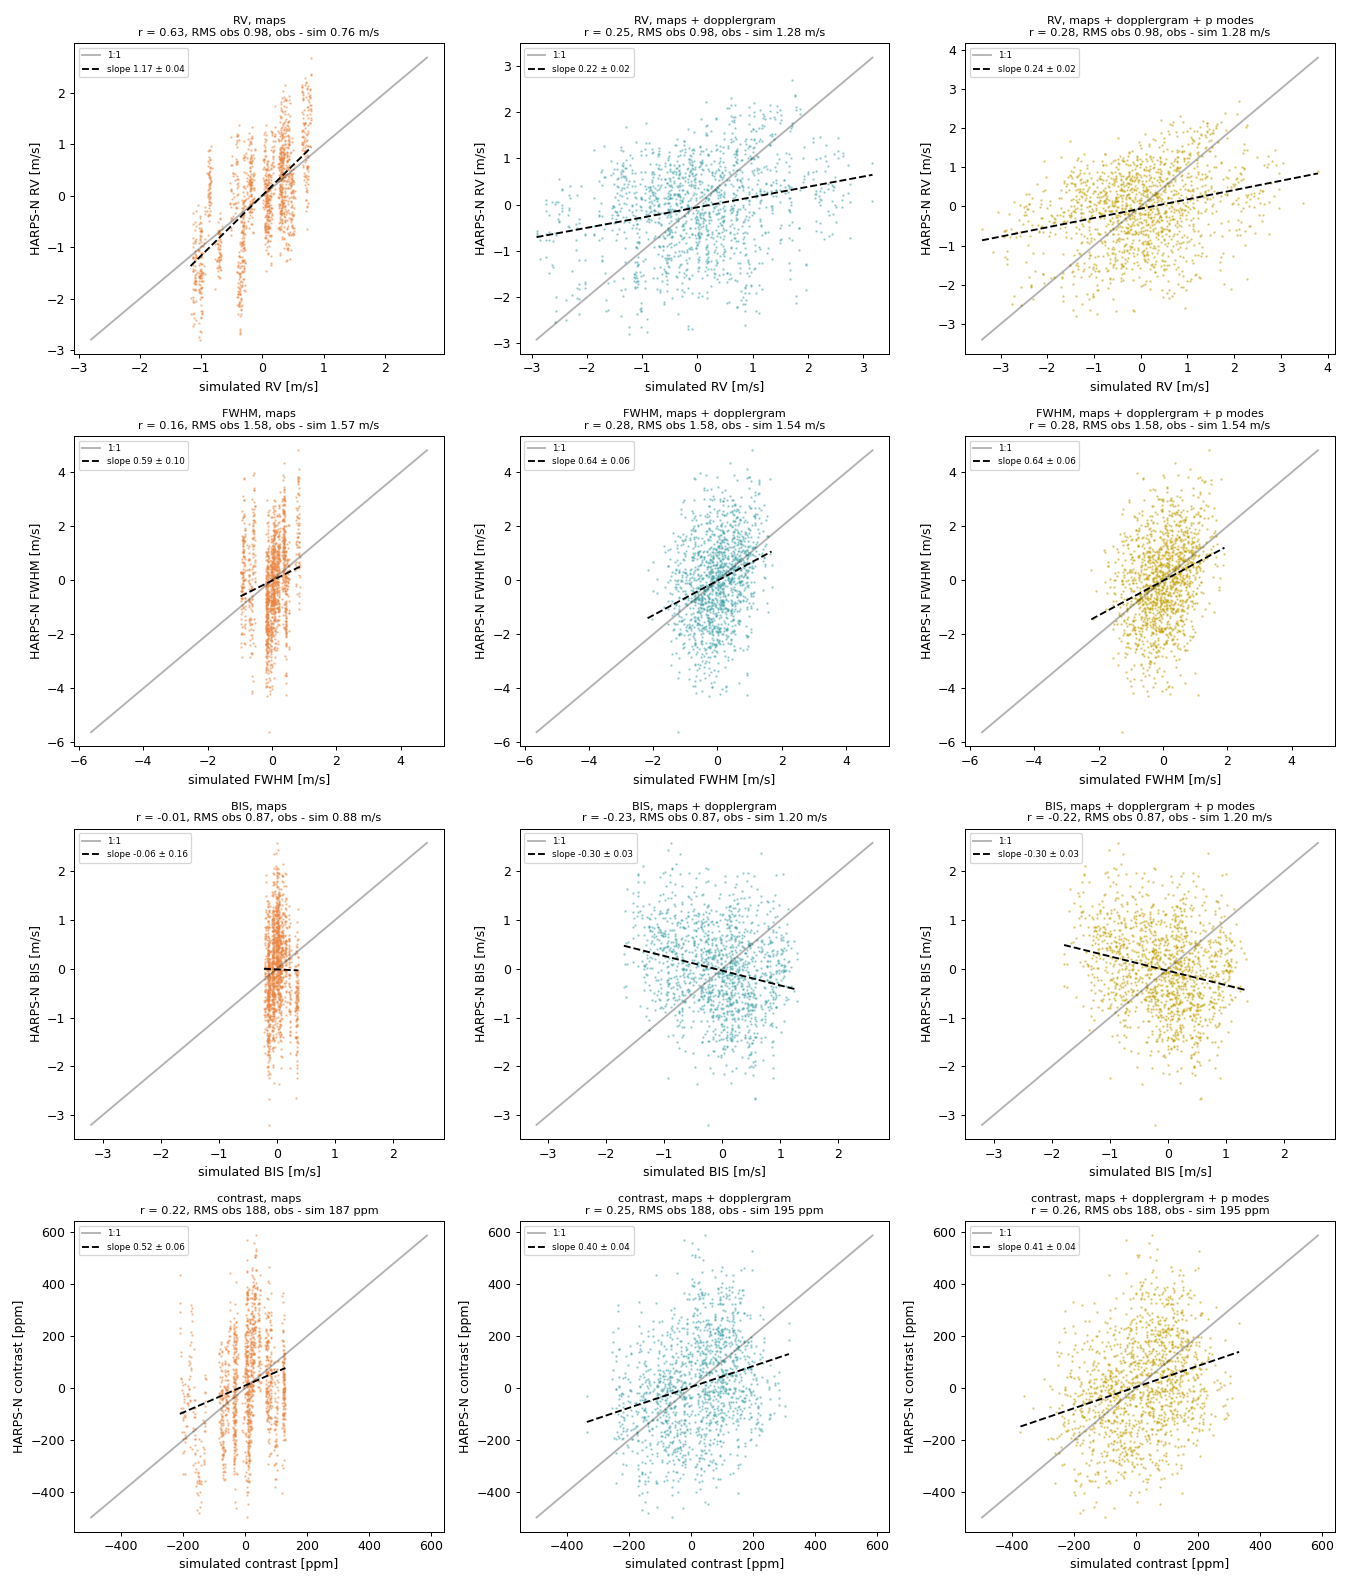

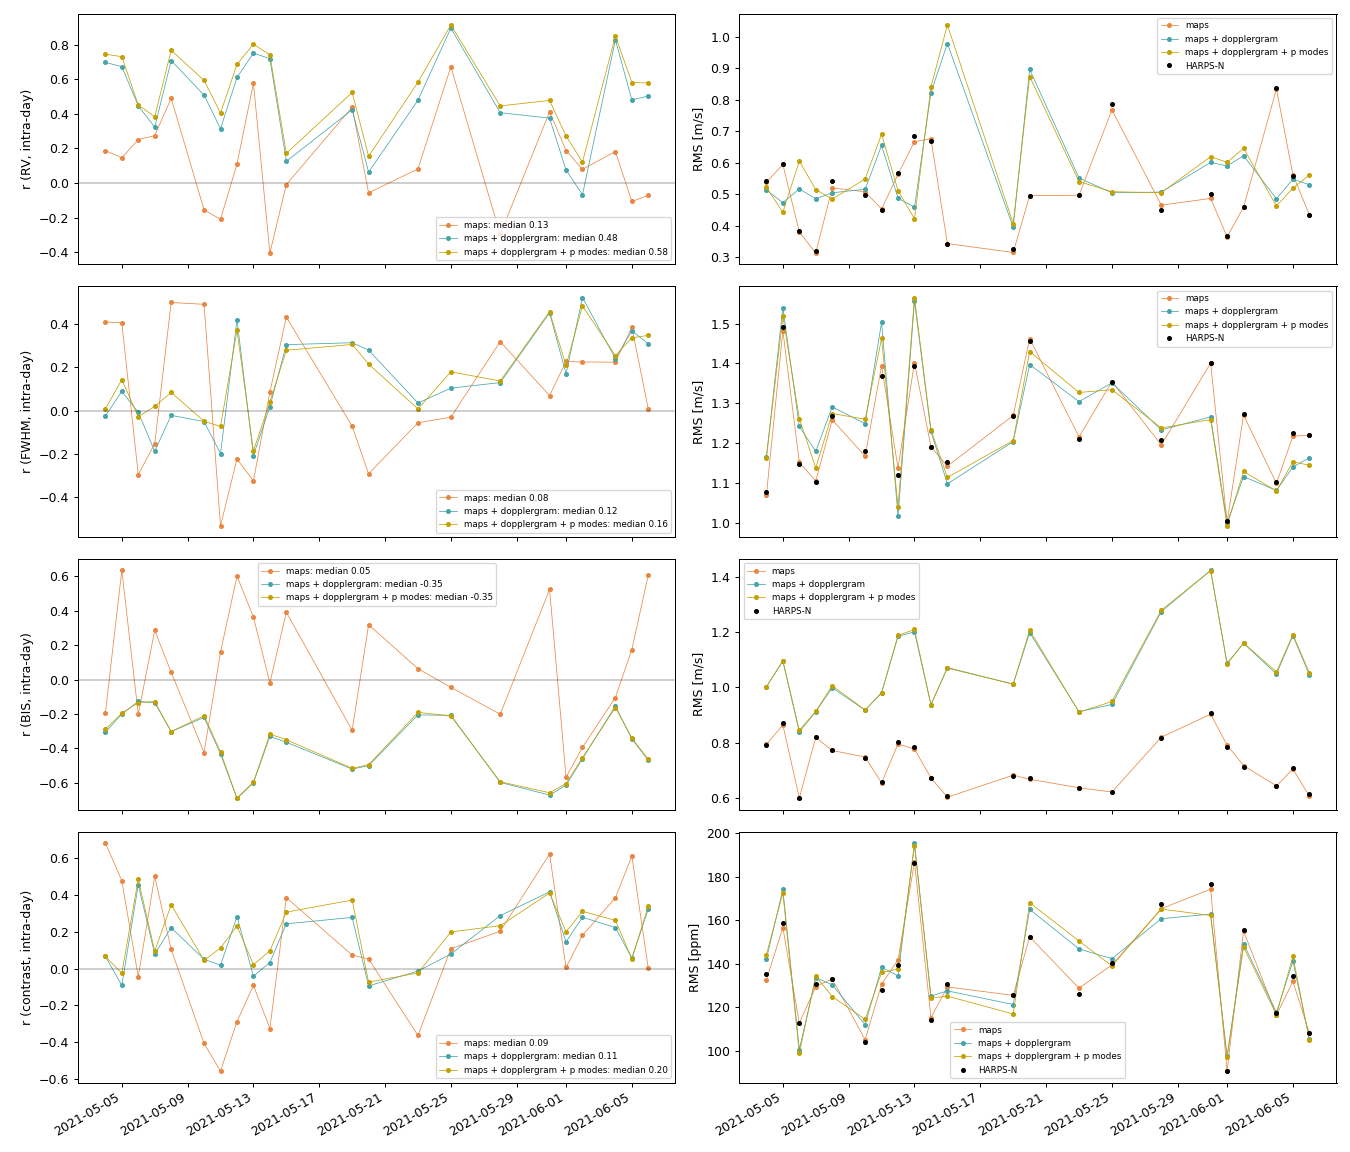

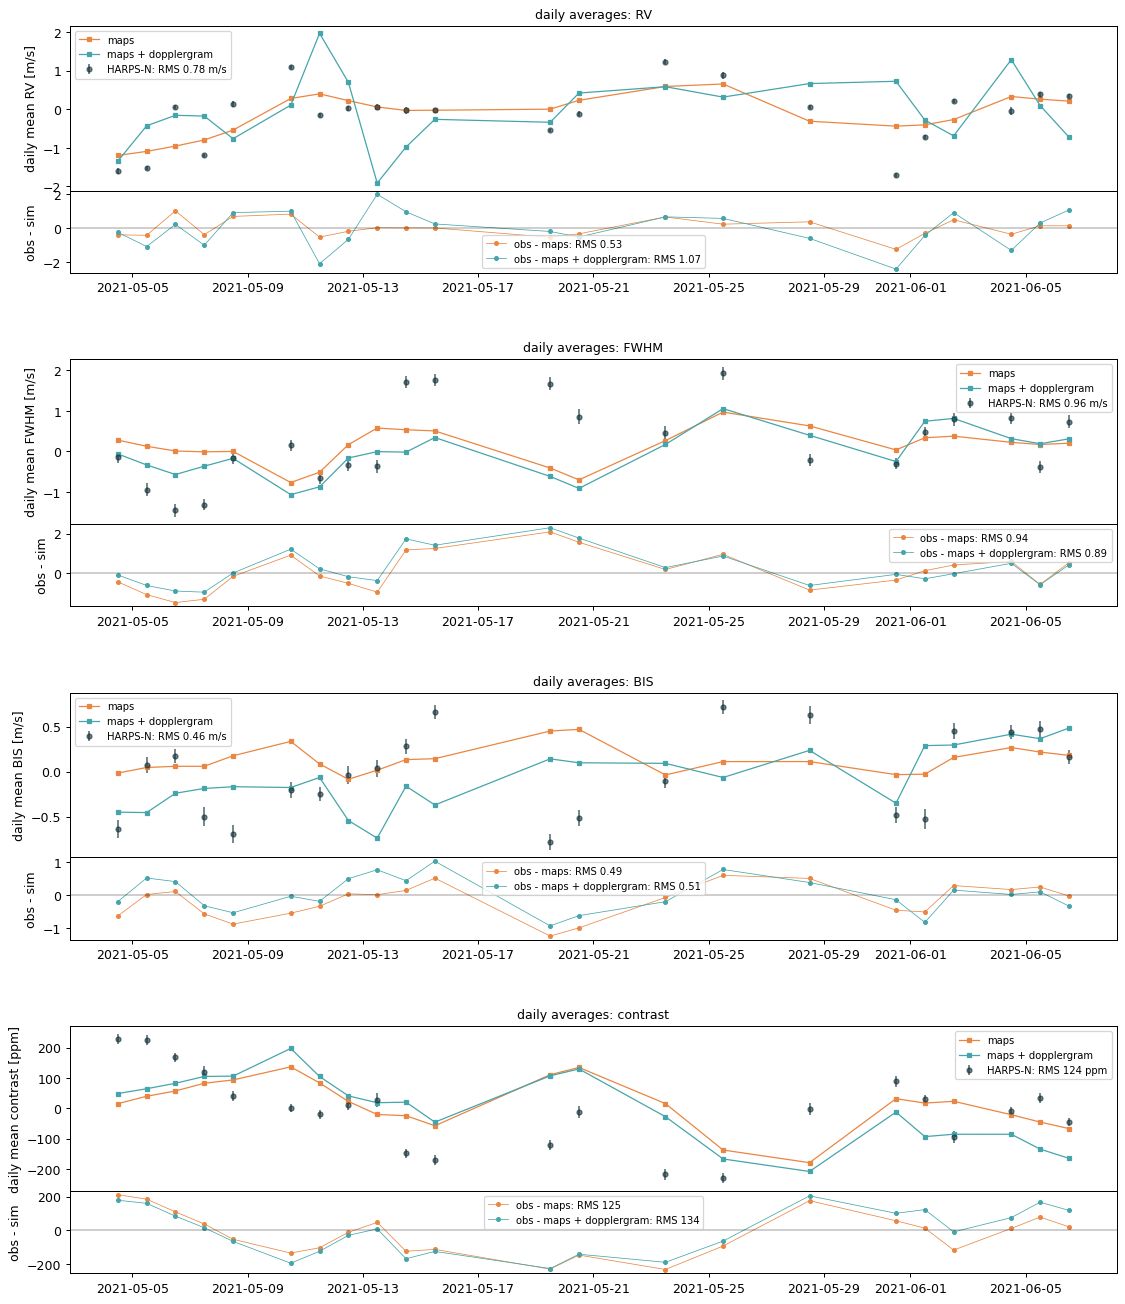

In [6]:
for f in ('full_correlation.png', 'per_day_r.png', 'daily_timeseries.png'):
    display(Image(os.path.join(OUT, QUAL, 'figures', f), width=1100))

## 4. How much does the threshold matter?

`collect` (tables only) for every threshold of `SCAN`, and the RMS of obs − sim within the day and the median r of the days for RV, FWHM and BIS, against the threshold (left: all the exposures).

14:06:54 quality: 53 of 2008 exposures left out (data_quality != 1: 0, not in the release: 0, obs_quality < 0.95: 53)
14:06:54 days with fewer than 50 exposures left: 11 (315 exposures)
14:06:54 1640 exposures on 24 days, 974 epochs, 45 s frames on 38 days
14:06:54 calibration: scale 0.9886-1.0188, north-south -71 to -32 m/s/R, disc velocity std 2.81 -> 1.13 m/s (OBS_VR polynomial of degree 2)
14:06:54 p modes for 1591 of 1640 exposures
14:06:55 3 simulations of 1640 exposures: 2 s
    quantity                         model  days  exposures  median r  days with r > 0 [%]  median slope  RMS obs (intra-day)  RMS obs - sim (intra-day)
0         rv                          maps    24       1640     0.154               75.000         3.132                0.535                      0.532
1         rv            maps + dopplergram    24       1640     0.480               95.833         0.397                0.535                      0.617
2         rv  maps + dopplergram + p modes    24      

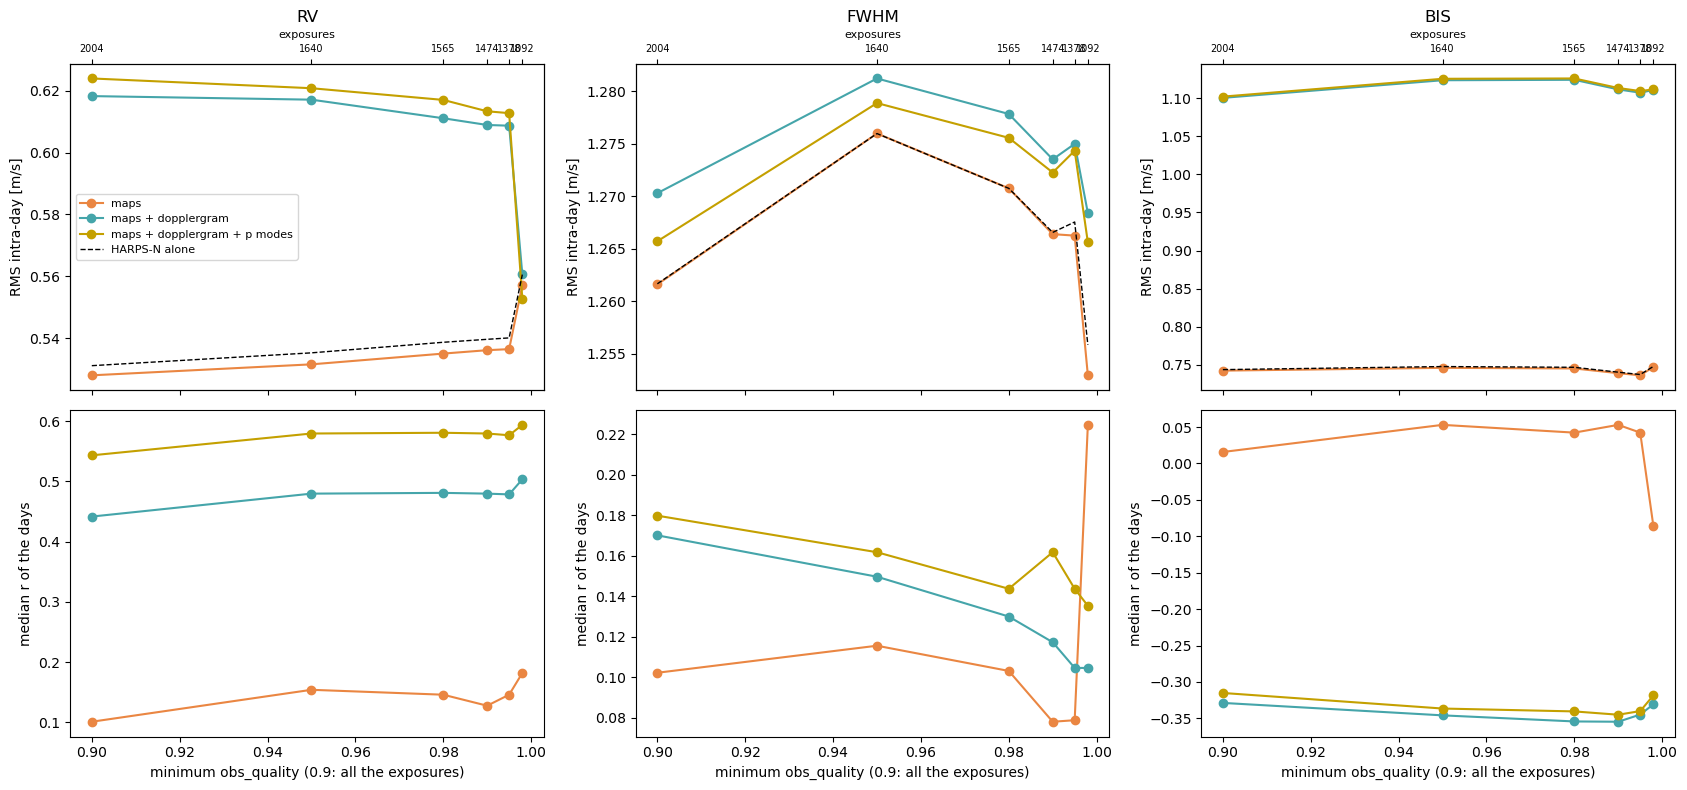

threshold                                0.900    0.950    0.980    0.990  \
quantity model                                                              
bis      maps                            0.742    0.746    0.745    0.739   
         maps + dopplergram              1.101    1.124    1.124    1.112   
         maps + dopplergram + p modes    1.102    1.126    1.126    1.114   
contrast maps                          142.173  143.471  142.424  140.674   
         maps + dopplergram            145.717  146.951  145.932  143.555   
         maps + dopplergram + p modes  145.494  146.543  145.705  143.355   
fwhm     maps                            1.262    1.276    1.271    1.266   
         maps + dopplergram              1.270    1.281    1.278    1.273   
         maps + dopplergram + p modes    1.266    1.279    1.276    1.272   
rv       maps                            0.528    0.532    0.535    0.536   
         maps + dopplergram              0.618    0.617    0.611    0.609   
         maps + dopplergram + p modes    0.624    0.621    0.617    0.613   

threshold                                0.995    0.998  
quantity model                                           
bis      maps                            0.736    0.747  
         maps + dopplergram              1.107    1.111  
         maps + dopplergram + p modes    1.110    1.112  
contrast maps                          140.659  139.751  
         maps + dopplergram            143.949  144.206  
         maps + dopplergram + p modes  143.734  143.755  
fwhm     maps                            1.266    1.253  
         maps + dopplergram              1.275    1.268  
         maps + dopplergram + p modes    1.274    1.266  
rv       maps                            0.536    0.557  
         maps + dopplergram              0.609    0.561  
         maps + dopplergram + p modes    0.613    0.553

In [7]:
rows = []
for q_min in [None] + SCAN:
    name = ALL if q_min is None else ('results_scan_%g_days%d' % (q_min, MIN_DAY_EXP) if q_min != MIN_OBS_QUALITY else QUAL)
    if q_min is not None and q_min != MIN_OBS_QUALITY:
        collect(name, q_min, figures=False, min_day_exp=MIN_DAY_EXP)
    t = table(name, 'intra_day_summary.csv')
    t['threshold'] = 0.9 if q_min is None else q_min
    rows.append(t)
scan = pd.concat(rows)
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for k, q in enumerate(('rv', 'fwhm', 'bis')):
    for name, col in (('maps', '#ea8642'), ('maps + dopplergram', '#45a5aa'), ('maps + dopplergram + p modes', '#c4a000')):
        s = scan[(scan['quantity'] == q) & (scan['model'] == name)].sort_values('threshold')
        axes[0, k].plot(s['threshold'], s['RMS obs - sim (intra-day)'], 'o-', color=col, label=name)
        axes[1, k].plot(s['threshold'], s['median r'], 'o-', color=col, label=name)
    s = scan[(scan['quantity'] == q) & (scan['model'] == 'maps')].sort_values('threshold')
    axes[0, k].plot(s['threshold'], s['RMS obs (intra-day)'], 'k--', lw=1, label='HARPS-N alone')
    axes[0, k].set_title(q.upper())
    axes[0, k].set_ylabel('RMS intra-day [m/s]'); axes[1, k].set_ylabel('median r of the days')
    axes[1, k].set_xlabel('minimum obs_quality (0.9: all the exposures)')
    ax2 = axes[0, k].twiny(); ax2.set_xlim(axes[0, k].get_xlim())
    ax2.set_xticks(s['threshold']); ax2.set_xticklabels(s['exposures'], fontsize=7); ax2.set_xlabel('exposures', fontsize=8)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT, QUAL, 'figures', 'threshold_scan.png'), dpi=150, bbox_inches='tight')
plt.show()
scan.pivot_table(index=['quantity', 'model'], columns='threshold', values='RMS obs - sim (intra-day)').round(3)

## 5. Every day, with the exposures of good quality only

The run `results_quality_<MIN_OBS_QUALITY>` (`data_quality` = 1 and `obs_quality` ≥ `MIN_OBS_QUALITY`, days with at least `MIN_DAY_EXP` exposures left), day by day: first the table of every day (exposures left, RMS of HARPS-N and of obs − sim, r of obs against sim, all within the day: median of the day removed), then one figure per indicator with one panel per day: HARPS-N (points, with their error bars) and the three simulations, each without its median of the day, and below it the residuals obs − sim of the three simulations.

In [8]:
pd_q = table(QUAL, 'per_day.csv')
pd_q = pd_q[pd_q['n'] >= 5]                                 # days with at least 5 exposures (min_exp of collect)
removed = table(QUAL, 'removed_exposures.csv')
n_all = pd.Series(ex['day']).value_counts()
wide = pd_q.pivot_table(index='day', columns=['quantity', 'model'], values=['RMS obs - sim', 'r'])
days_q = pd_q[pd_q['quantity'] == 'rv'].drop_duplicates('day').set_index('day')
per_day_tab = pd.DataFrame({'exposures (all)': n_all.reindex(days_q.index), 'exposures kept': days_q['n'],
                            'RMS obs RV': days_q['RMS obs']})
am = table(QUAL, 'exposures.csv').groupby('day')['airmass']
per_day_tab['airmass min'], per_day_tab['airmass max'] = am.min(), am.max()
for q in ('rv', 'fwhm', 'bis'):
    for name, short in (('maps', 'maps'), ('maps + dopplergram', '+ doppler.'), ('maps + dopplergram + p modes', '+ p modes')):
        per_day_tab['%s %s: RMS obs - sim' % (q.upper(), short)] = wide[('RMS obs - sim', q, name)]
        per_day_tab['%s %s: r' % (q.upper(), short)] = wide[('r', q, name)]
per_day_tab.to_csv(os.path.join(OUT, QUAL, 'per_day_table.csv'))
print('%d days with exposures of good quality (of %d); days left out entirely: %s'
      % (len(per_day_tab), len(n_all), ', '.join(sorted(set(n_all.index) - set(per_day_tab.index)))))
per_day_tab.round(2)

22 days with exposures of good quality (of 38); days left out entirely: 2021-05-01, 2021-05-02, 2021-05-03, 2021-05-09, 2021-05-16, 2021-05-18, 2021-05-21, 2021-05-22, 2021-05-24, 2021-05-26, 2021-05-29, 2021-05-30, 2021-06-08, 2021-06-09, 2021-06-10, 2021-06-12


,exposures (all),exposures kept,RMS obs RV,airmass min,airmass max,RV maps: RMS obs - sim,RV maps: r,RV + doppler.: RMS obs - sim,RV + doppler.: r,RV + p modes: RMS obs - sim,...,FWHM + doppler.: RMS obs - sim,FWHM + doppler.: r,FWHM + p modes: RMS obs - sim,FWHM + p modes: r,BIS maps: RMS obs - sim,BIS maps: r,BIS + doppler.: RMS obs - sim,BIS + doppler.: r,BIS + p modes: RMS obs - sim,BIS + p modes: r
day,,,,,,,,,,,,,,,,,,,,,
2021-05-04,61,61,0.54,1.03,1.73,0.54,0.19,0.51,0.70,0.52,...,1.17,-0.02,1.16,0.01,0.79,-0.20,1.00,-0.31,1.00,-0.29
2021-05-05,98,98,0.60,1.02,2.69,0.59,0.15,0.47,0.67,0.44,...,1.54,0.09,1.52,0.14,0.86,0.64,1.09,-0.20,1.10,-0.20
2021-05-06,60,60,0.38,1.02,2.02,0.38,0.25,0.52,0.45,0.60,...,1.24,-0.01,1.26,-0.03,0.60,-0.20,0.84,-0.13,0.84,-0.13
2021-05-07,62,60,0.32,1.02,1.46,0.31,0.27,0.49,0.32,0.51,...,1.18,-0.19,1.14,0.02,0.82,0.29,0.91,-0.13,0.91,-0.13
2021-05-08,60,60,0.54,1.02,1.60,0.52,0.49,0.50,0.71,0.48,...,1.29,-0.02,1.27,0.09,0.77,0.04,1.00,-0.30,1.01,-0.30
2021-05-10,68,66,0.50,1.02,1.73,0.51,-0.16,0.52,0.51,0.55,...,1.25,-0.05,1.26,-0.05,0.75,-0.42,0.92,-0.22,0.92,-0.21
2021-05-11,82,69,0.45,1.02,2.06,0.45,-0.21,0.65,0.31,0.69,...,1.50,-0.20,1.46,-0.07,0.65,0.16,0.98,-0.43,0.98,-0.42
2021-05-12,77,64,0.57,1.02,1.83,0.56,0.11,0.49,0.61,0.51,...,1.02,0.42,1.04,0.37,0.80,0.60,1.18,-0.69,1.19,-0.69
2021-05-13,77,76,0.68,1.02,2.78,0.67,0.58,0.46,0.75,0.42,...,1.56,-0.21,1.56,-0.19,0.78,0.36,1.20,-0.60,1.21,-0.60


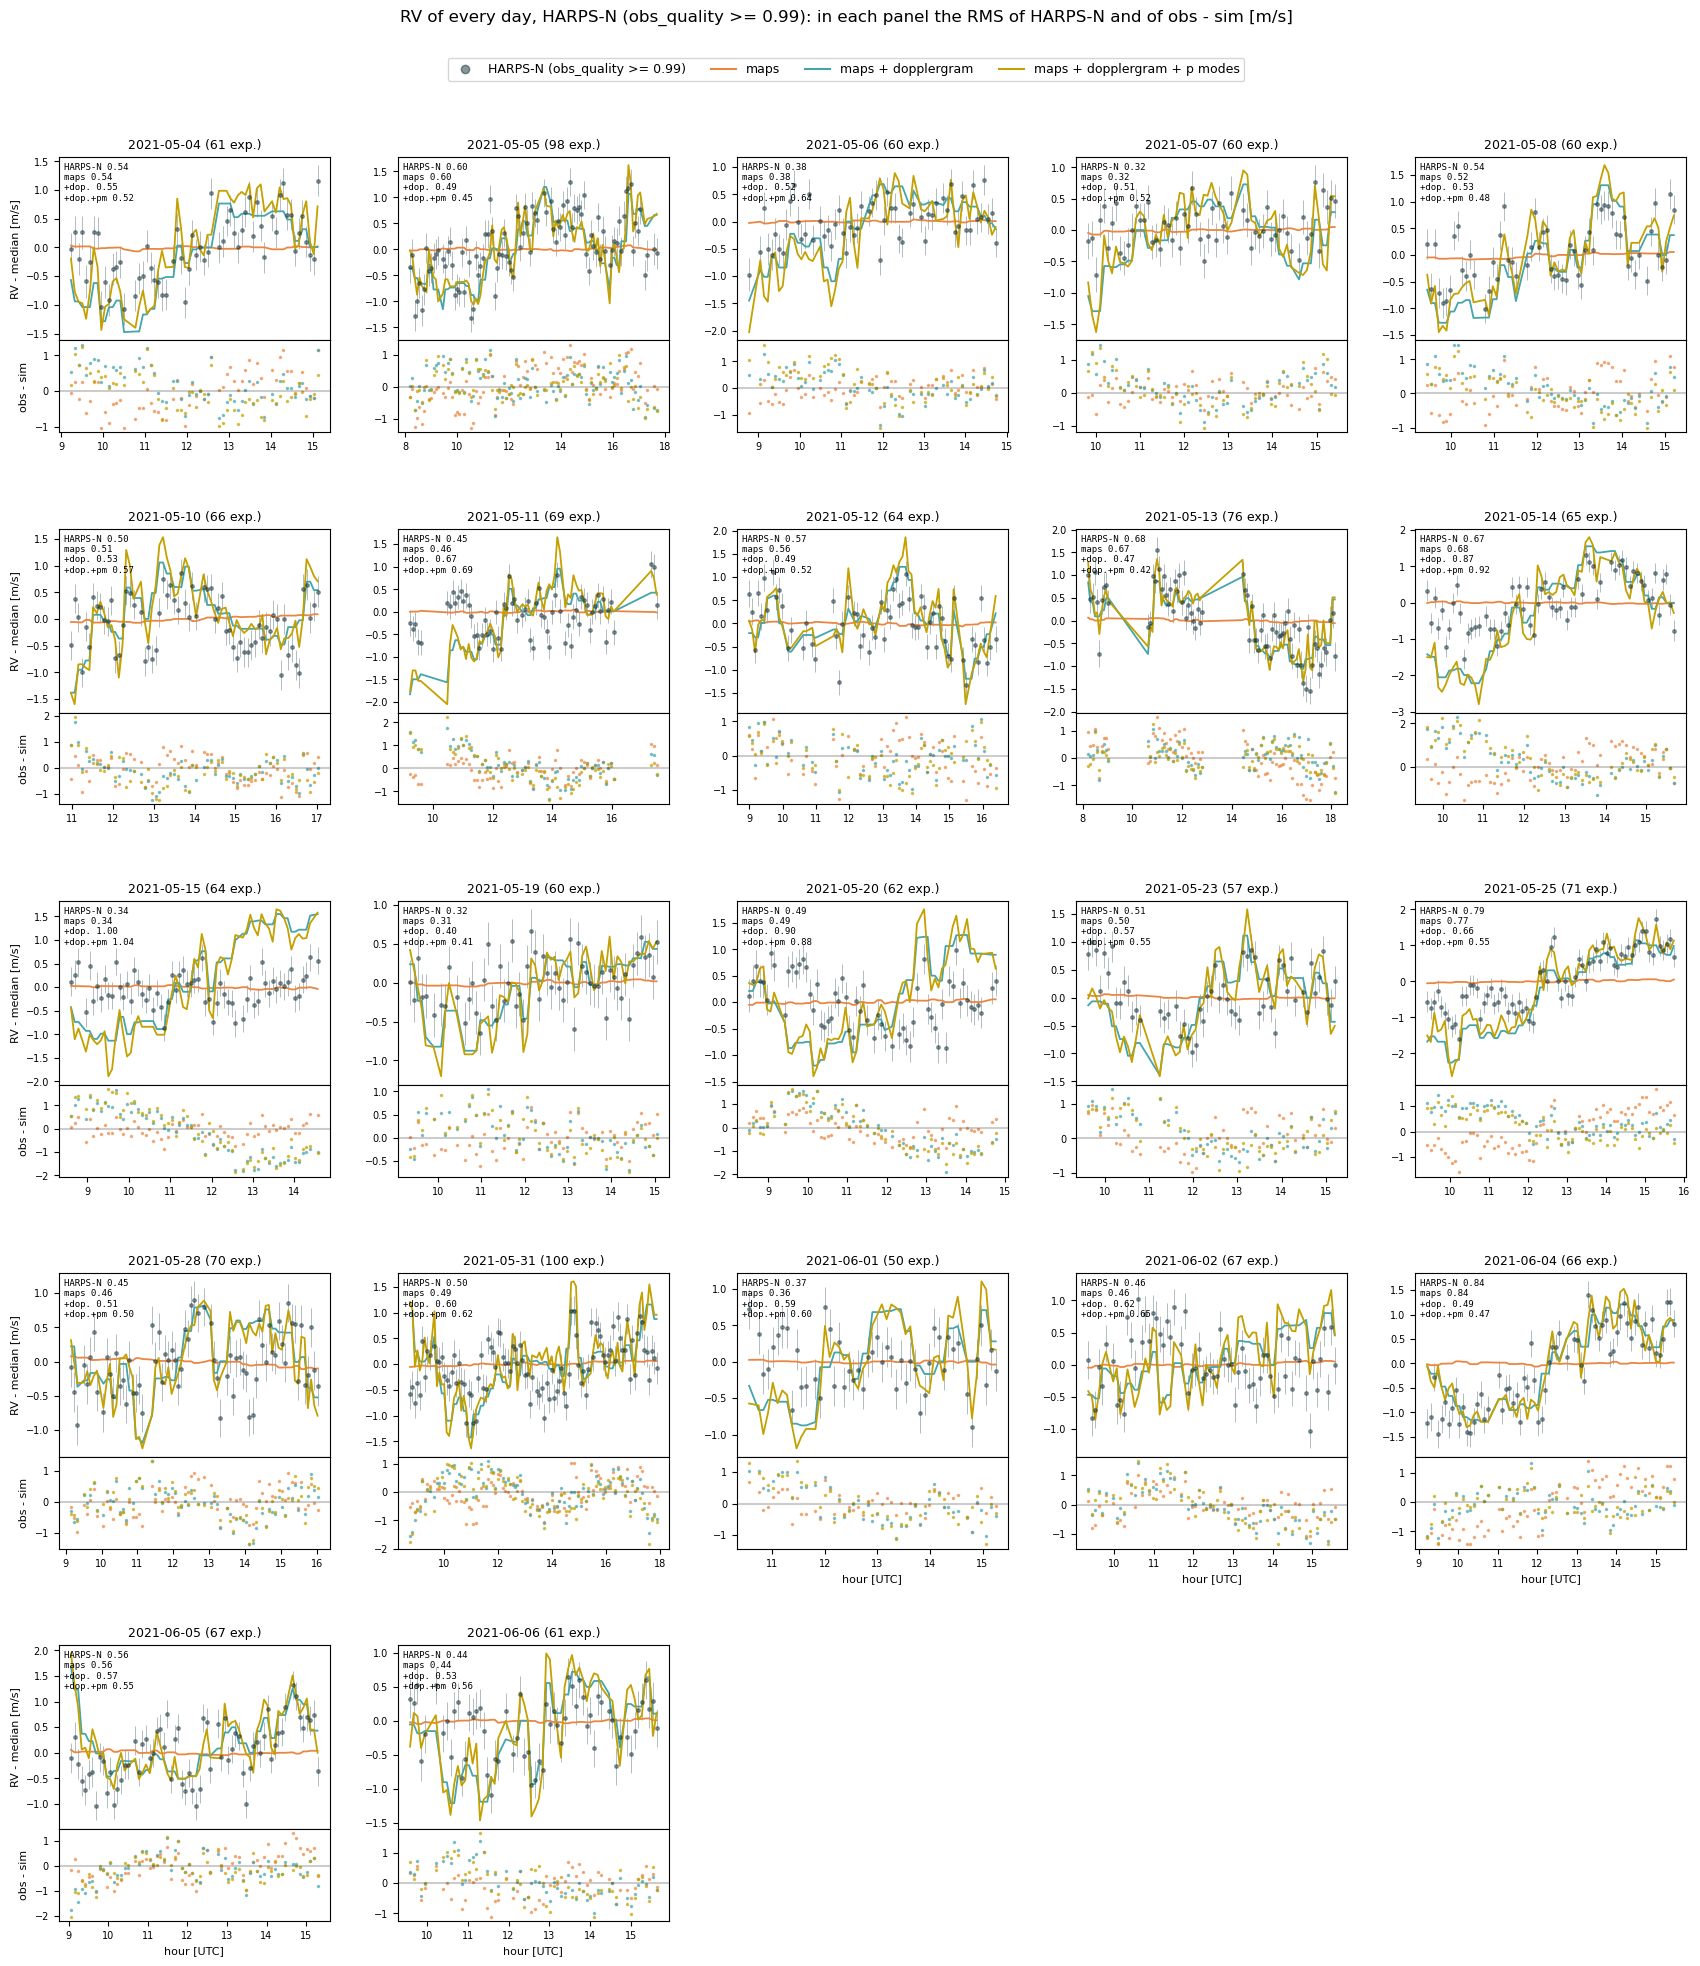

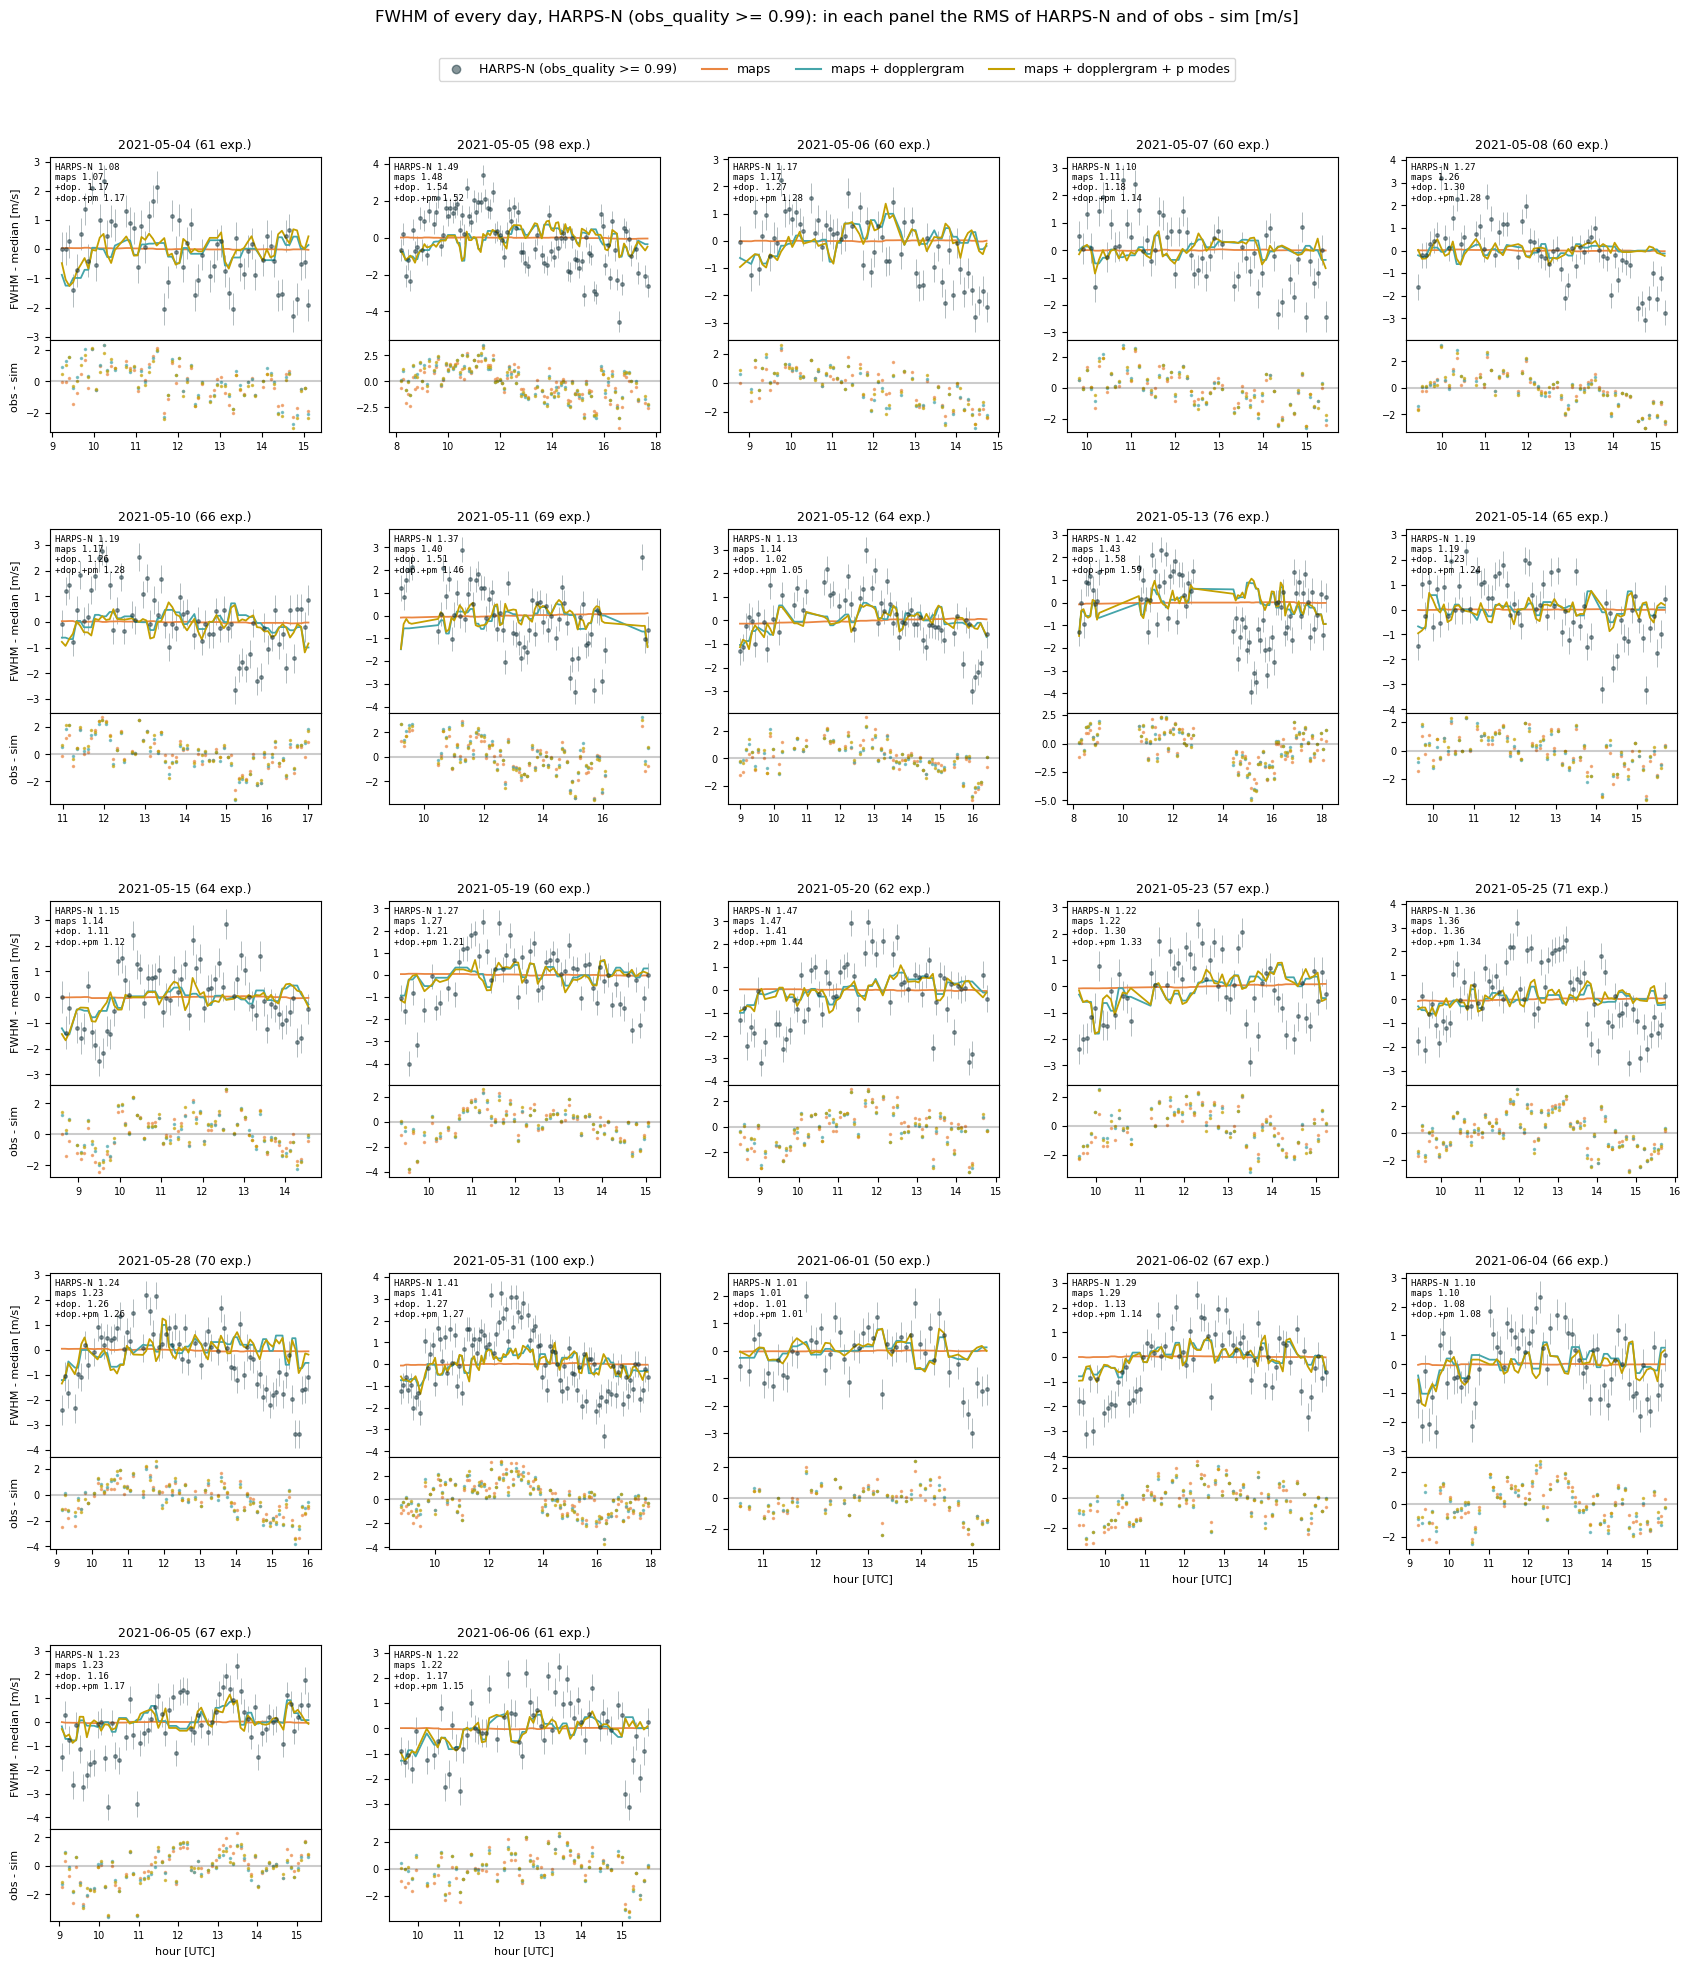

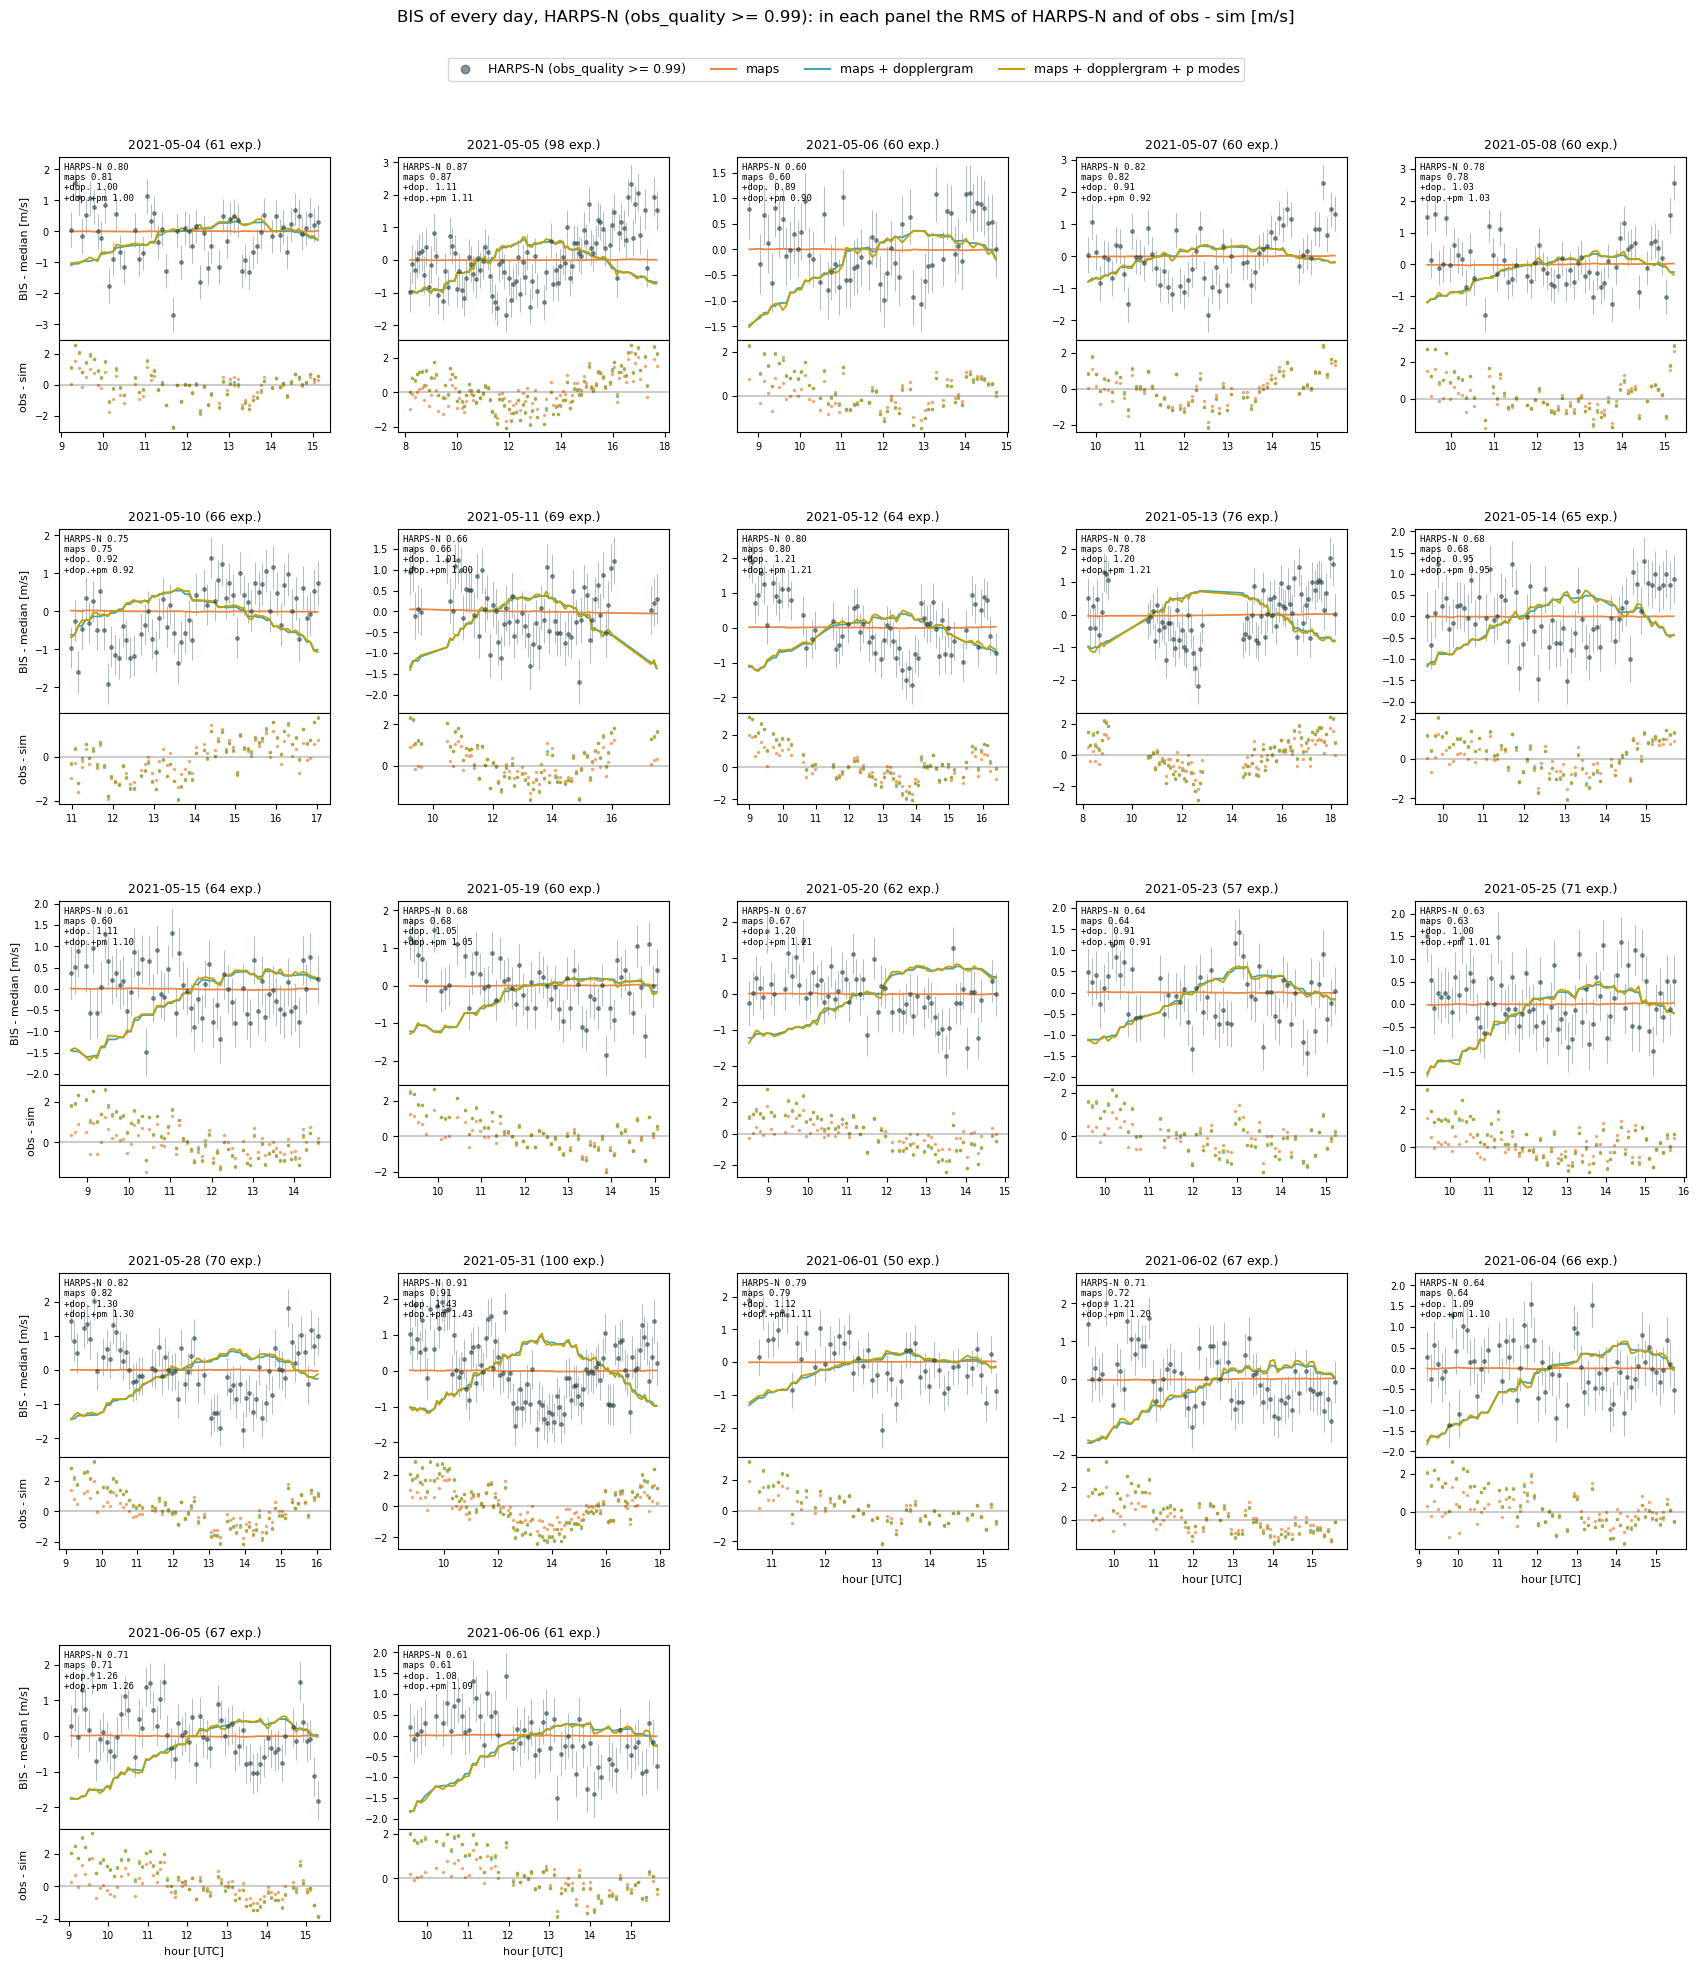

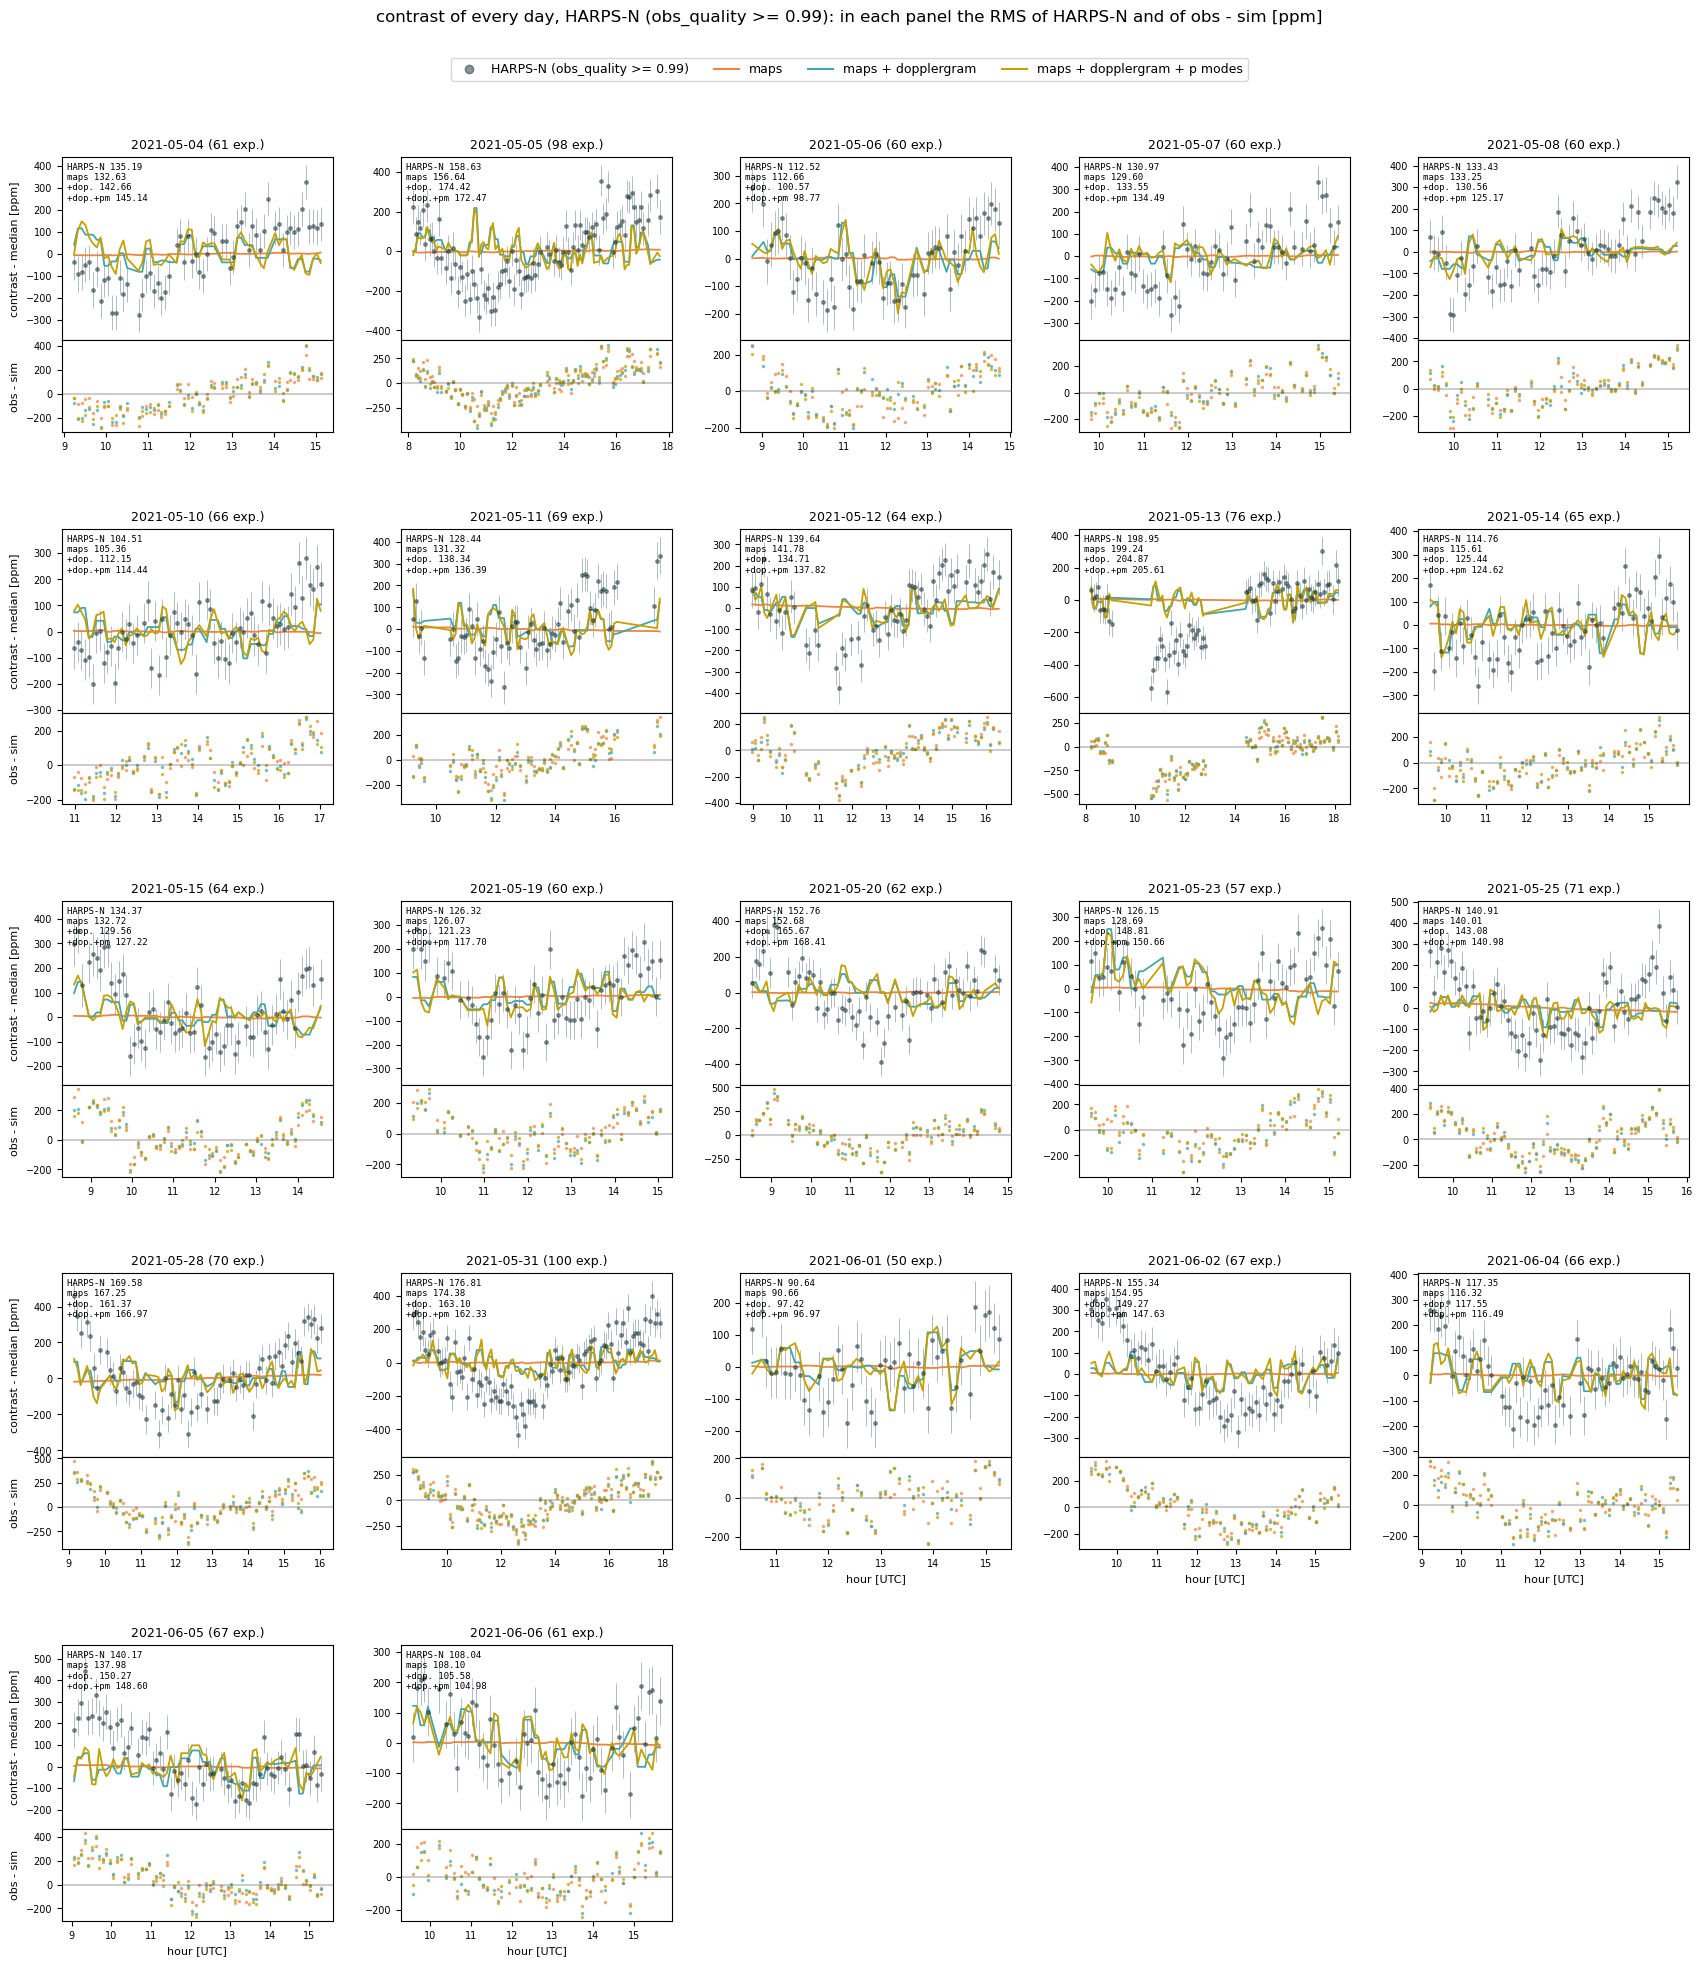

In [ ]:
exq = table(QUAL, 'exposures.csv')
MODELS = (('maps', 'maps', '#ea8642'), ('maps_dopplergram', 'maps + dopplergram', '#45a5aa'),
          ('maps_dopplergram_p_modes', 'maps + dopplergram + p modes', '#c4a000'))
LABEL = {'rv': 'RV', 'fwhm': 'FWHM', 'bis': 'BIS', 'contrast': 'contrast'}
UNIT = {'rv': 'm/s', 'fwhm': 'm/s', 'bis': 'm/s', 'contrast': 'ppm'}
days5 = list(per_day_tab.index)
ncol = 5
nrow = int(np.ceil(len(days5) / ncol))

def every_day(e_all, obs='obs', what='HARPS-N (obs_quality >= %g)' % MIN_OBS_QUALITY, fname='every_day_%s.png'):
    """One figure per indicator, one panel per day of days5: HARPS-N (column <q>_<obs> of e_all) and the three
    simulations, each without its median of the day, and below the residuals obs - sim."""
    for q in ('rv', 'fwhm', 'bis', 'contrast'):
        fig = plt.figure(figsize=(4.2 * ncol, 4.2 * nrow))
        outer = fig.add_gridspec(nrow, ncol, hspace=0.35, wspace=0.25, top=0.95)
        for k, d in enumerate(days5):
            inner = outer[k // ncol, k % ncol].subgridspec(2, 1, height_ratios=[2, 1], hspace=0)
            ax, ar = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
            ar.sharex(ax)
            e = e_all[e_all['day'] == d]
            h = (e['jd_utc'] + 0.5) % 1 * 24
            o = e[q + '_' + obs] - e[q + '_' + obs].median()
            ax.errorbar(h, o, yerr=e[q + '_err'], fmt='o', ms=2.5, color='#102e37', alpha=0.45, lw=0.5)
            txt = ['HARPS-N %.2f' % np.sqrt(np.mean(o ** 2))]
            for col, name, colour in MODELS:
                s = e['%s_%s' % (q, col)] - e['%s_%s' % (q, col)].median()
                ax.plot(h, s, '-', color=colour, lw=1.3)
                ar.plot(h, o - s, 'o', ms=1.5, color=colour, alpha=0.6)
                txt.append('%s %.2f' % (name.replace('maps + dopplergram', '+dop.').replace(' + p modes', '+pm'), np.sqrt(np.mean((o - s) ** 2))))
            ar.axhline(0, color='k', alpha=0.2)
            ax.set_title('%s (%d exp.)' % (d, len(e)), fontsize=9)
            ax.text(0.02, 0.97, '\n'.join(txt), transform=ax.transAxes, va='top', fontsize=6.5, family='monospace')
            ax.tick_params(labelsize=7, labelbottom=False); ar.tick_params(labelsize=7)
            if k % ncol == 0:
                ax.set_ylabel('%s - median [%s]' % (LABEL[q], UNIT[q]), fontsize=8)
                ar.set_ylabel('obs - sim', fontsize=8)
            if k >= len(days5) - ncol:
                ar.set_xlabel('hour [UTC]', fontsize=8)
        handles = [plt.Line2D([], [], color='#102e37', marker='o', ls='', alpha=0.5, label=what)]
        handles += [plt.Line2D([], [], color=c, label=n) for _, n, c in MODELS]
        fig.legend(handles=handles, loc='upper center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.0))
        fig.suptitle('%s of every day, %s: in each panel the RMS of HARPS-N and of obs - sim [%s]' % (LABEL[q], what, UNIT[q]),
                     y=1.02)
        plt.savefig(os.path.join(OUT, QUAL, 'figures', fname % q), dpi=130, bbox_inches='tight')
        plt.show()

every_day(exq)

#todo plot also the correction to see if we remove or miss something

### 5.1 Airmass of the exposures kept

The airmass of every exposure (from the release, in `exposures.csv` and `removed_exposures.csv` of `collect`): kept in colour (one colour per day), left out in grey. Right: the residuals within the day (obs − maps + dopplergram, median of the day removed) against the airmass, with their RMS in bins of airmass (black).

airmass of the 1474 exposures kept: 1.01 to 2.78 (median 1.10); of the 534 left out: median 1.14


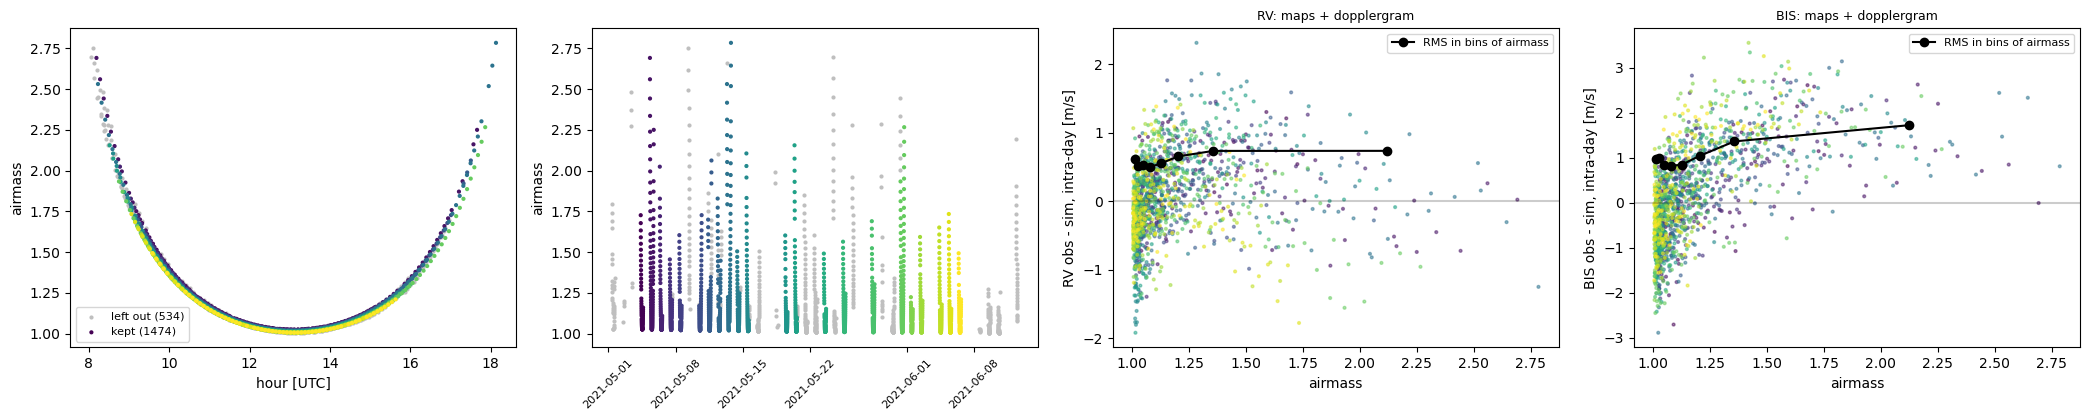

In [10]:
kept = table(QUAL, 'exposures.csv')
removed = table(QUAL, 'removed_exposures.csv')
print('airmass of the %d exposures kept: %.2f to %.2f (median %.2f); of the %d left out: median %.2f'
      % (len(kept), kept['airmass'].min(), kept['airmass'].max(), kept['airmass'].median(), len(removed),
         removed['airmass'].median()))
day_idx = kept['day'].map({d: i for i, d in enumerate(sorted(kept['day'].unique()))})
date = lambda jd: pd.to_datetime(jd - 2440587.5, unit='D')
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
ax = axes[0]
ax.scatter((removed['jd_utc'] + 0.5) % 1 * 24, removed['airmass'], s=4, color='0.75', label='left out (%d)' % len(removed))
ax.scatter((kept['jd_utc'] + 0.5) % 1 * 24, kept['airmass'], s=4, c=day_idx, cmap='viridis', label='kept (%d)' % len(kept))
ax.set_xlabel('hour [UTC]'); ax.set_ylabel('airmass'); ax.legend(fontsize=8)
ax = axes[1]
ax.scatter(date(removed['jd_utc']), removed['airmass'], s=4, color='0.75', label='left out')
ax.scatter(date(kept['jd_utc']), kept['airmass'], s=4, c=day_idx, cmap='viridis', label='kept')
ax.set_ylabel('airmass'); ax.tick_params(axis='x', labelrotation=45, labelsize=8)
for ax, q in zip(axes[2:], ('rv', 'bis')):
    res = (kept[q + '_obs'] - kept.groupby('day')[q + '_obs'].transform('median')) \
        - (kept[q + '_maps_dopplergram'] - kept.groupby('day')[q + '_maps_dopplergram'].transform('median'))
    ax.scatter(kept['airmass'], res, s=4, c=day_idx, cmap='viridis', alpha=0.5)
    bins = np.quantile(kept['airmass'], np.linspace(0, 1, 9))
    k = np.clip(np.digitize(kept['airmass'], bins) - 1, 0, len(bins) - 2)
    ax.plot(0.5 * (bins[1:] + bins[:-1]), [np.sqrt(np.mean(res[k == i] ** 2)) for i in range(len(bins) - 1)], 'ko-',
            label='RMS in bins of airmass')
    ax.axhline(0, color='k', alpha=0.2)
    ax.set_xlabel('airmass'); ax.set_ylabel('%s obs - sim, intra-day [m/s]' % q.upper()); ax.legend(fontsize=8)
    ax.set_title('%s: maps + dopplergram' % q.upper(), fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT, QUAL, 'figures', 'airmass.png'), dpi=130, bbox_inches='tight')
plt.show()

### 5.2 Correction of the airmass

A linear term in the airmass fitted to HARPS-N for every indicator, on the exposures kept: q_obs = offset of the day + b (X − 1) + k q_sim (least squares, X: airmass, q_sim: maps + dopplergram). The simulation is in the fit because it can also change with the hour (and so with X): without it, b takes part of the signal (column `b (no sim)`). The offsets of the days are only in the fit: the corrected values are q_obs − b (X − 1), so the daily means are corrected too. The error of b assumes independent residuals (the exposures of a day are not, so it is too small). The corrected values are in `exposures_airmass.csv` (columns `<q>_obs_airmass`).

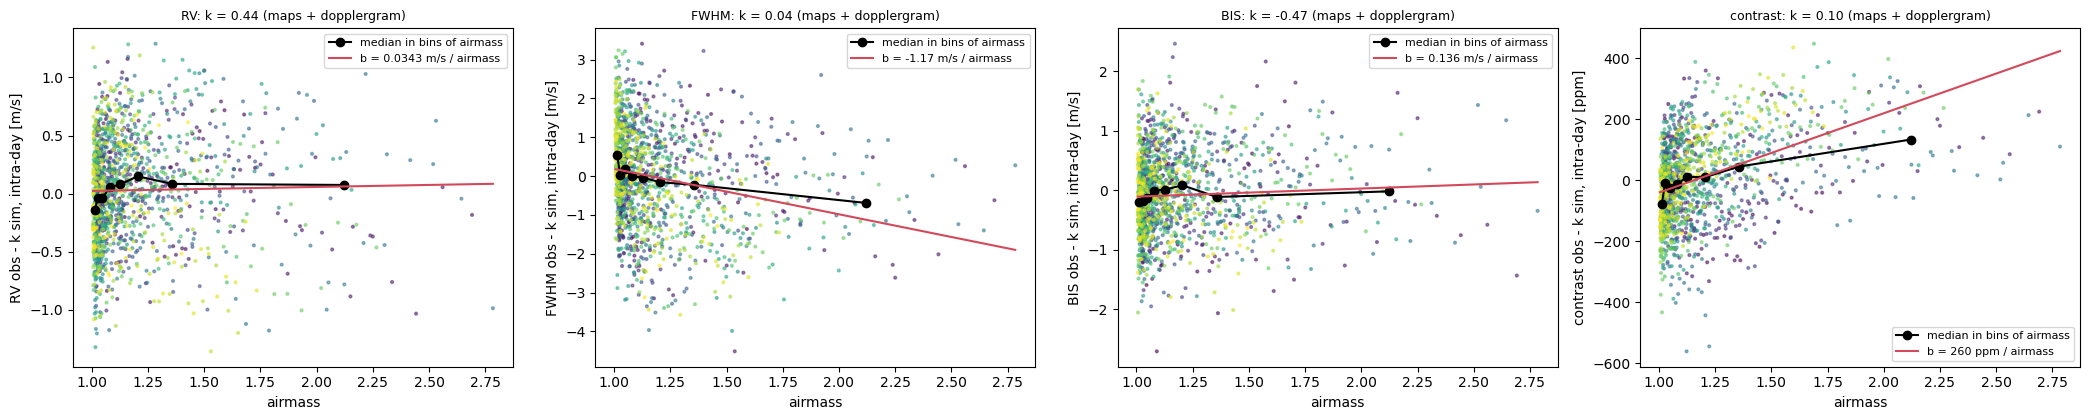

quantity,rv,fwhm,bis,contrast
b [per airmass],0.034,-1.169,0.136,259.844
error of b,0.052,0.172,0.129,14.227
b (no sim),-0.305,-1.215,1.037,264.897
k,0.439,0.043,-0.468,0.099
RMS obs (before),0.540,1.267,0.740,141.206
RMS obs (after),0.541,1.230,0.730,125.423
RMS obs - maps (before),0.536,1.266,0.739,140.674
RMS obs - maps (after),0.537,1.231,0.729,125.257
RMS obs - maps + dopplergram (before),0.609,1.273,1.112,143.555
RMS obs - maps + dopplergram (after),0.608,1.294,1.092,134.049


In [11]:
def detrend_airmass(q_obs, q_sim, X, day):
    """Least squares q_obs = offset of the day + b (X - 1) + k q_sim (no k if q_sim is None): q_obs - b (X - 1), b, error
    of b, k."""
    days = np.unique(day)
    A = np.column_stack([(day == d).astype(float) for d in days] + [X - 1] + ([] if q_sim is None else [q_sim]))
    coef, *_ = np.linalg.lstsq(A, q_obs, rcond=None)
    res = q_obs - A @ coef
    cov = np.sum(res ** 2) / (len(q_obs) - A.shape[1]) * np.linalg.inv(A.T @ A)
    i = len(days)
    return q_obs - coef[i] * (X - 1), coef[i], np.sqrt(cov[i, i]), (np.nan if q_sim is None else coef[i + 1])

def intra_k(x):
    return x - x.groupby(kept['day']).transform('median')

X, day = kept['airmass'].values, kept['day'].values
fits, rows = {}, []
for q in LABEL:
    kept[q + '_obs_airmass'], b, b_err, k = detrend_airmass(kept[q + '_obs'].values, kept['%s_%s' % (q, MODEL)].values, X, day)
    fits[q] = b, k
    row = {'quantity': q, 'b [per airmass]': b, 'error of b': b_err,
           'b (no sim)': detrend_airmass(kept[q + '_obs'].values, None, X, day)[1], 'k': k,
           'RMS obs (before)': np.sqrt(np.mean(intra_k(kept[q + '_obs']) ** 2)),
           'RMS obs (after)': np.sqrt(np.mean(intra_k(kept[q + '_obs_airmass']) ** 2))}
    for col, name, _ in MODELS:
        s = intra_k(kept['%s_%s' % (q, col)])
        for when, o in (('before', kept[q + '_obs']), ('after', kept[q + '_obs_airmass'])):
            row['RMS obs - %s (%s)' % (name, when)] = np.sqrt(np.mean((intra_k(o) - s) ** 2))
    rows.append(row)
kept.to_csv(os.path.join(OUT, QUAL, 'exposures_airmass.csv'), index=False)

# HARPS-N within the day minus k x the simulation, against the airmass, and the fitted b (X - 1)
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
for ax, q in zip(axes, LABEL):
    b, k = fits[q]
    y = intra_k(kept[q + '_obs']) - k * intra_k(kept['%s_%s' % (q, MODEL)])
    ax.scatter(X, y, s=4, c=day_idx, cmap='viridis', alpha=0.5)
    bins = np.quantile(X, np.linspace(0, 1, 9))
    kb = np.clip(np.digitize(X, bins) - 1, 0, len(bins) - 2)
    ax.plot(0.5 * (bins[1:] + bins[:-1]), [np.median(y[kb == i]) for i in range(len(bins) - 1)], 'ko-',
            label='median in bins of airmass')
    xx = np.linspace(X.min(), X.max(), 2)
    ax.plot(xx, b * (xx - 1) - np.median(b * (X - 1) - y), '-', color='#d1495b', label='b = %.3g %s / airmass' % (b, UNIT[q]))
    ax.set_xlabel('airmass'); ax.set_ylabel('%s obs - k sim, intra-day [%s]' % (LABEL[q], UNIT[q])); ax.legend(fontsize=8)
    ax.set_title('%s: k = %.2f (maps + dopplergram)' % (LABEL[q], k), fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT, QUAL, 'figures', 'airmass_correction.png'), dpi=130, bbox_inches='tight')
plt.show()
pd.DataFrame(rows).set_index('quantity').T.round(3)

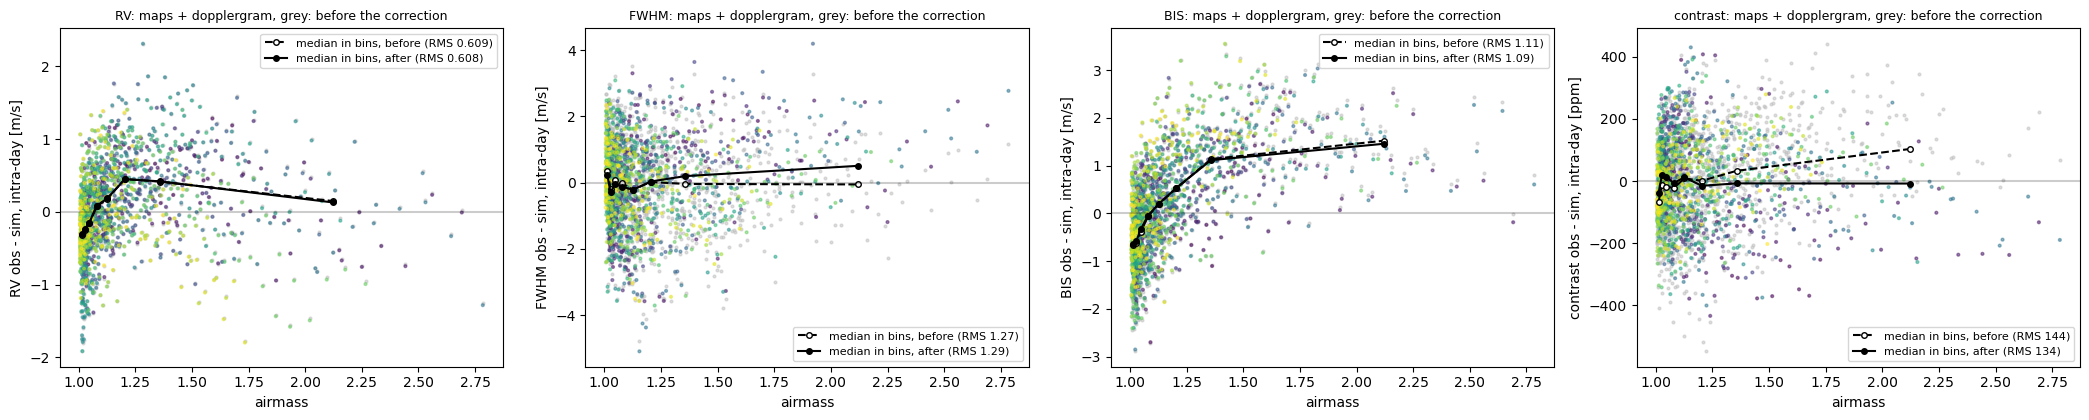

In [12]:
# obs - maps + dopplergram within the day against the airmass: before (grey) and after (colour) the correction
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
bins = np.quantile(X, np.linspace(0, 1, 9))
kb = np.clip(np.digitize(X, bins) - 1, 0, len(bins) - 2)
xb = 0.5 * (bins[1:] + bins[:-1])
for ax, q in zip(axes, LABEL):
    s = intra_k(kept['%s_%s' % (q, MODEL)])
    before = intra_k(kept[q + '_obs']) - s
    after = intra_k(kept[q + '_obs_airmass']) - s
    ax.scatter(X, before, s=4, color='0.75', alpha=0.5)
    ax.scatter(X, after, s=4, c=day_idx, cmap='viridis', alpha=0.5)
    for y, fmt, when in ((before, 'o--', 'before'), (after, 'o-', 'after')):
        ax.plot(xb, [np.median(y[kb == i]) for i in range(len(bins) - 1)], fmt, color='k', ms=4,
                mfc='white' if when == 'before' else 'k',
                label='median in bins, %s (RMS %.3g)' % (when, np.sqrt(np.mean(y ** 2))))
    ax.axhline(0, color='k', alpha=0.2)
    ax.set_xlabel('airmass'); ax.set_ylabel('%s obs - sim, intra-day [%s]' % (LABEL[q], UNIT[q])); ax.legend(fontsize=8)
    ax.set_title('%s: maps + dopplergram, grey: before the correction' % LABEL[q], fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT, QUAL, 'figures', 'airmass_after_correction.png'), dpi=130, bbox_inches='tight')
plt.show()

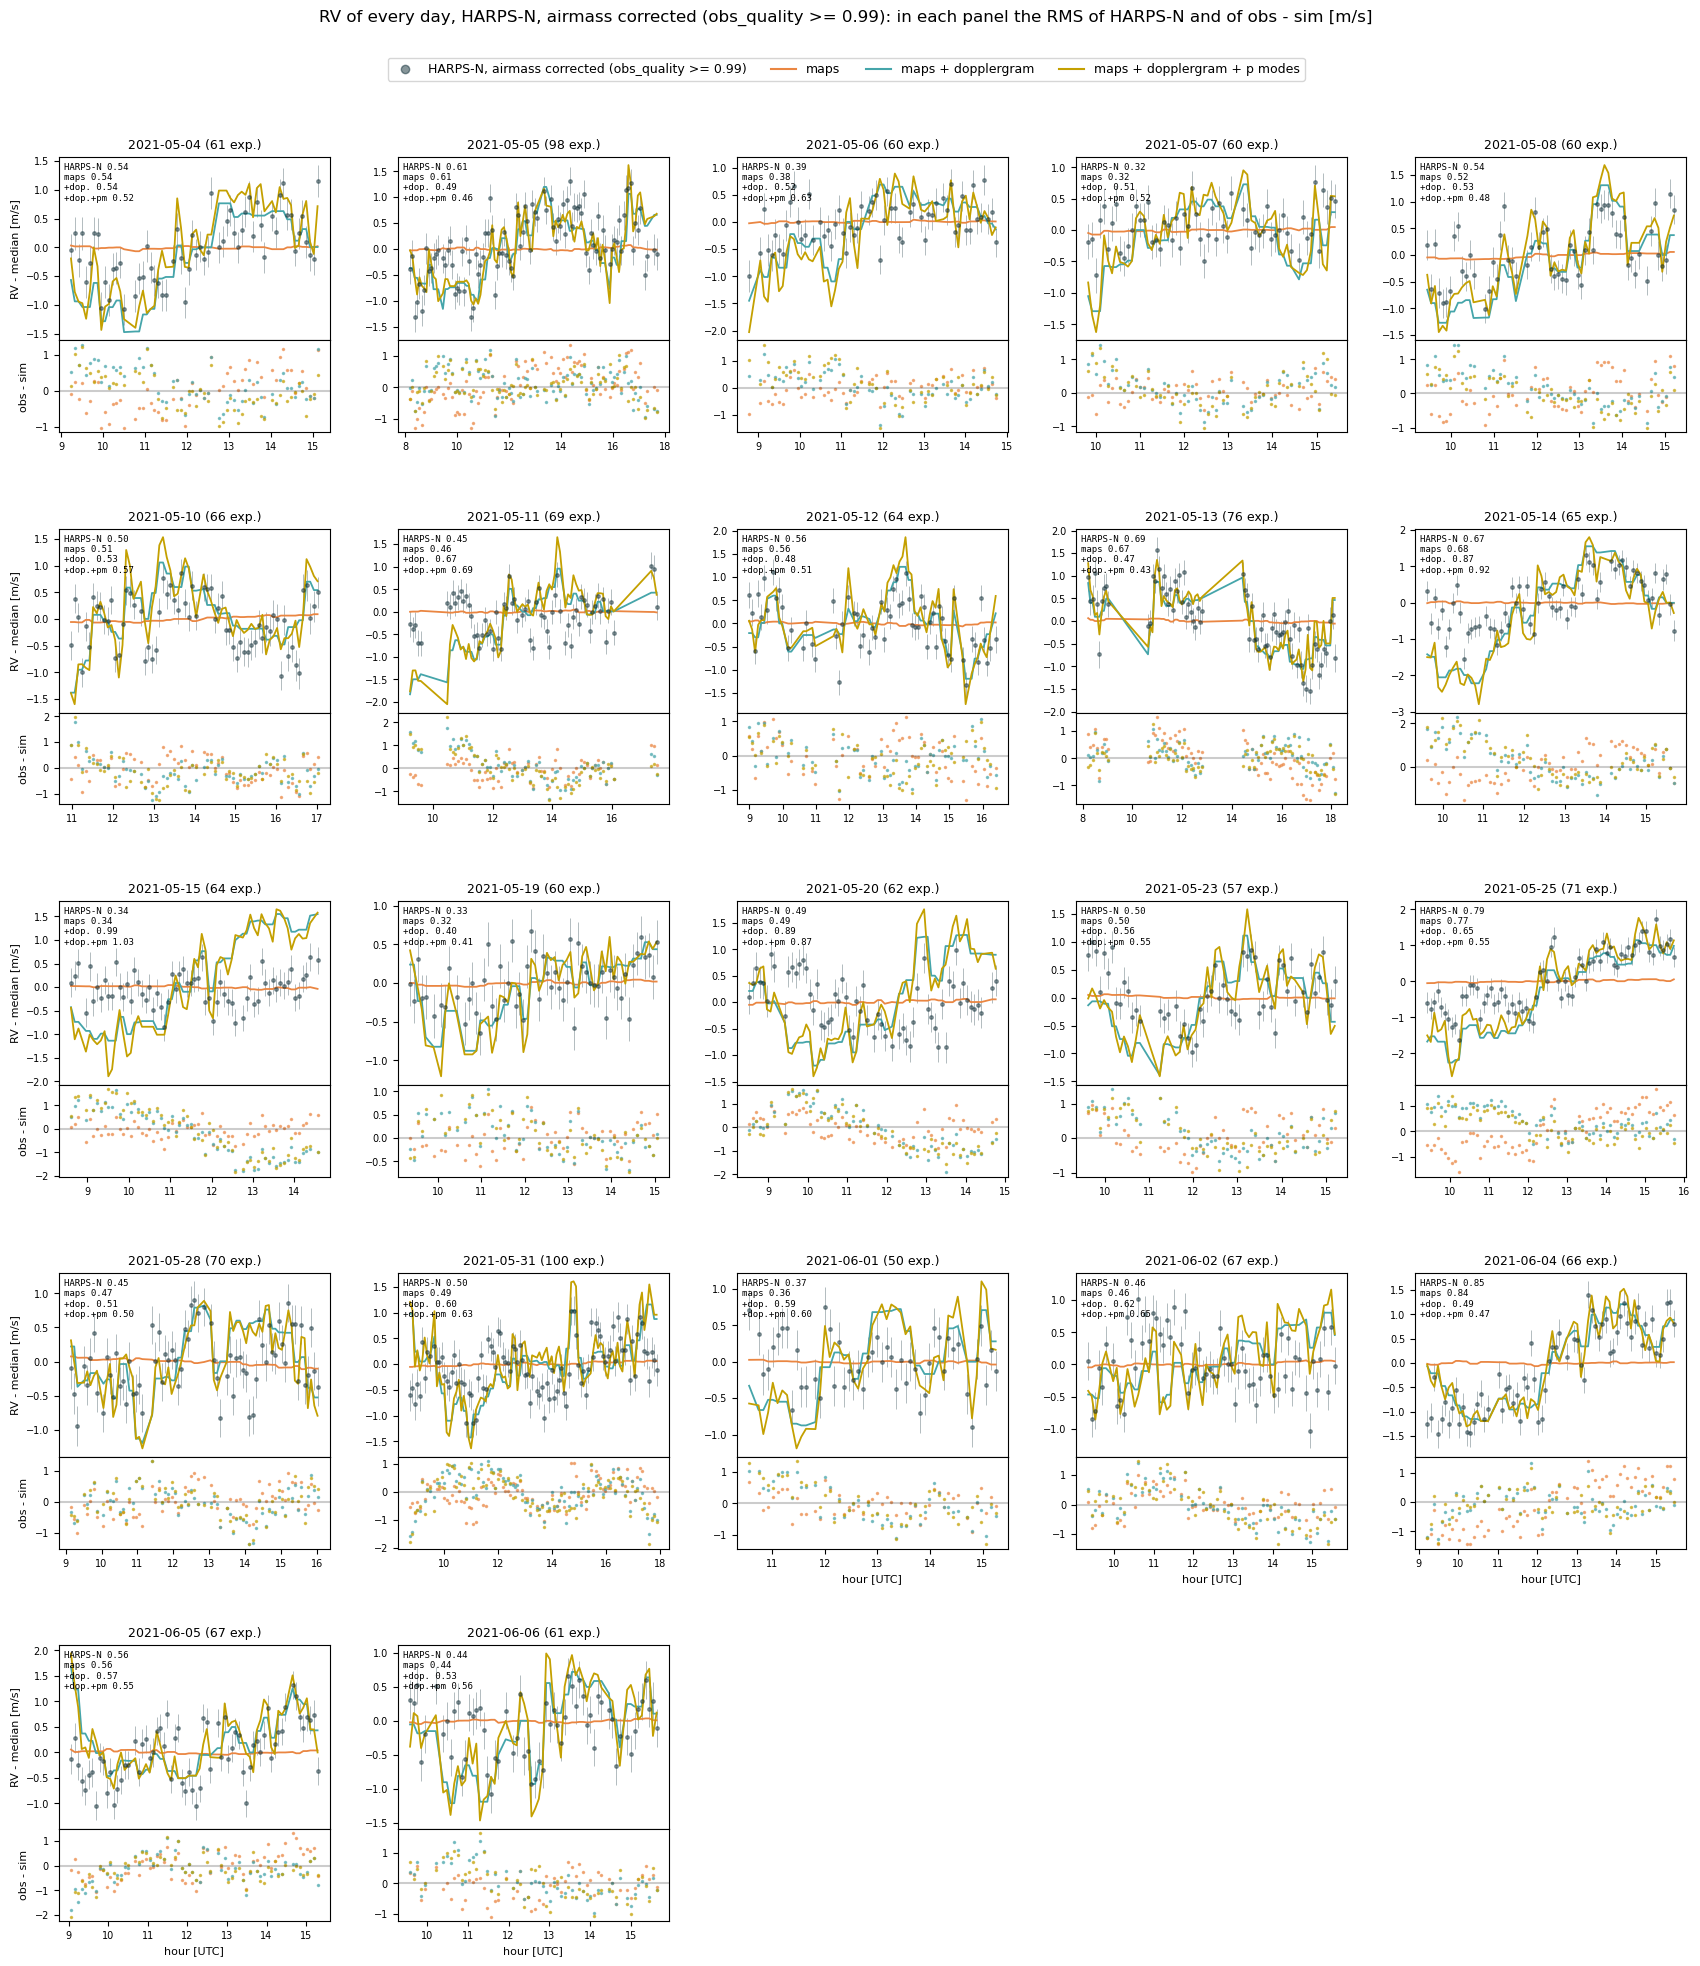

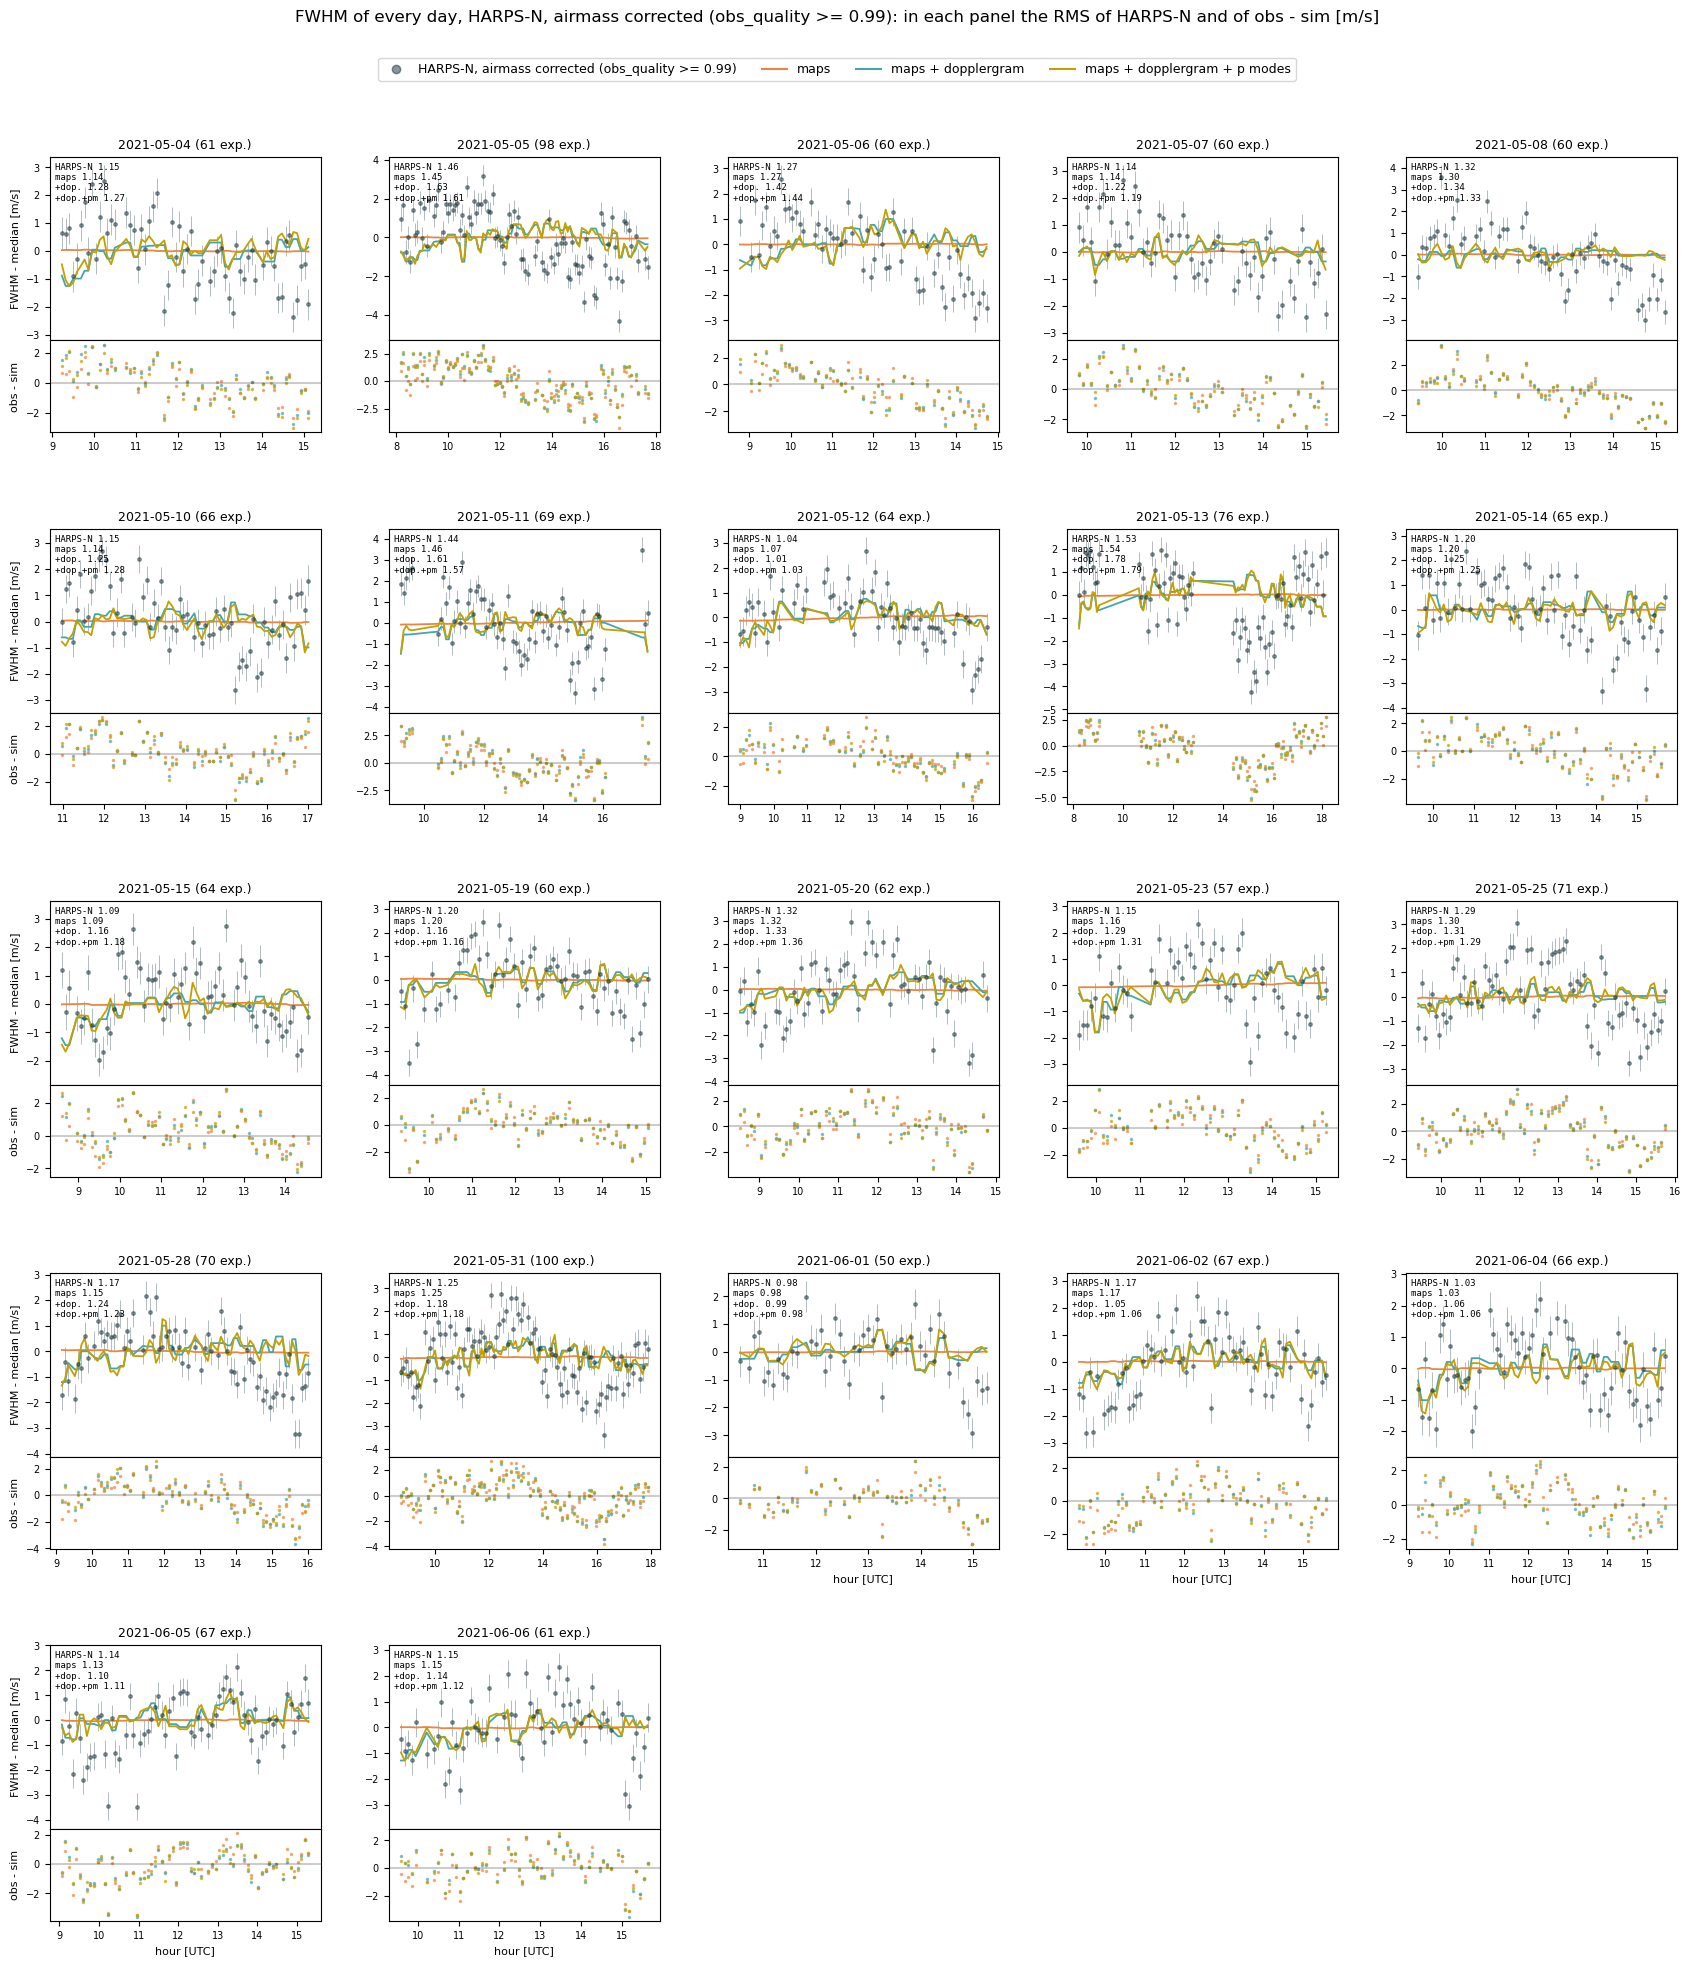

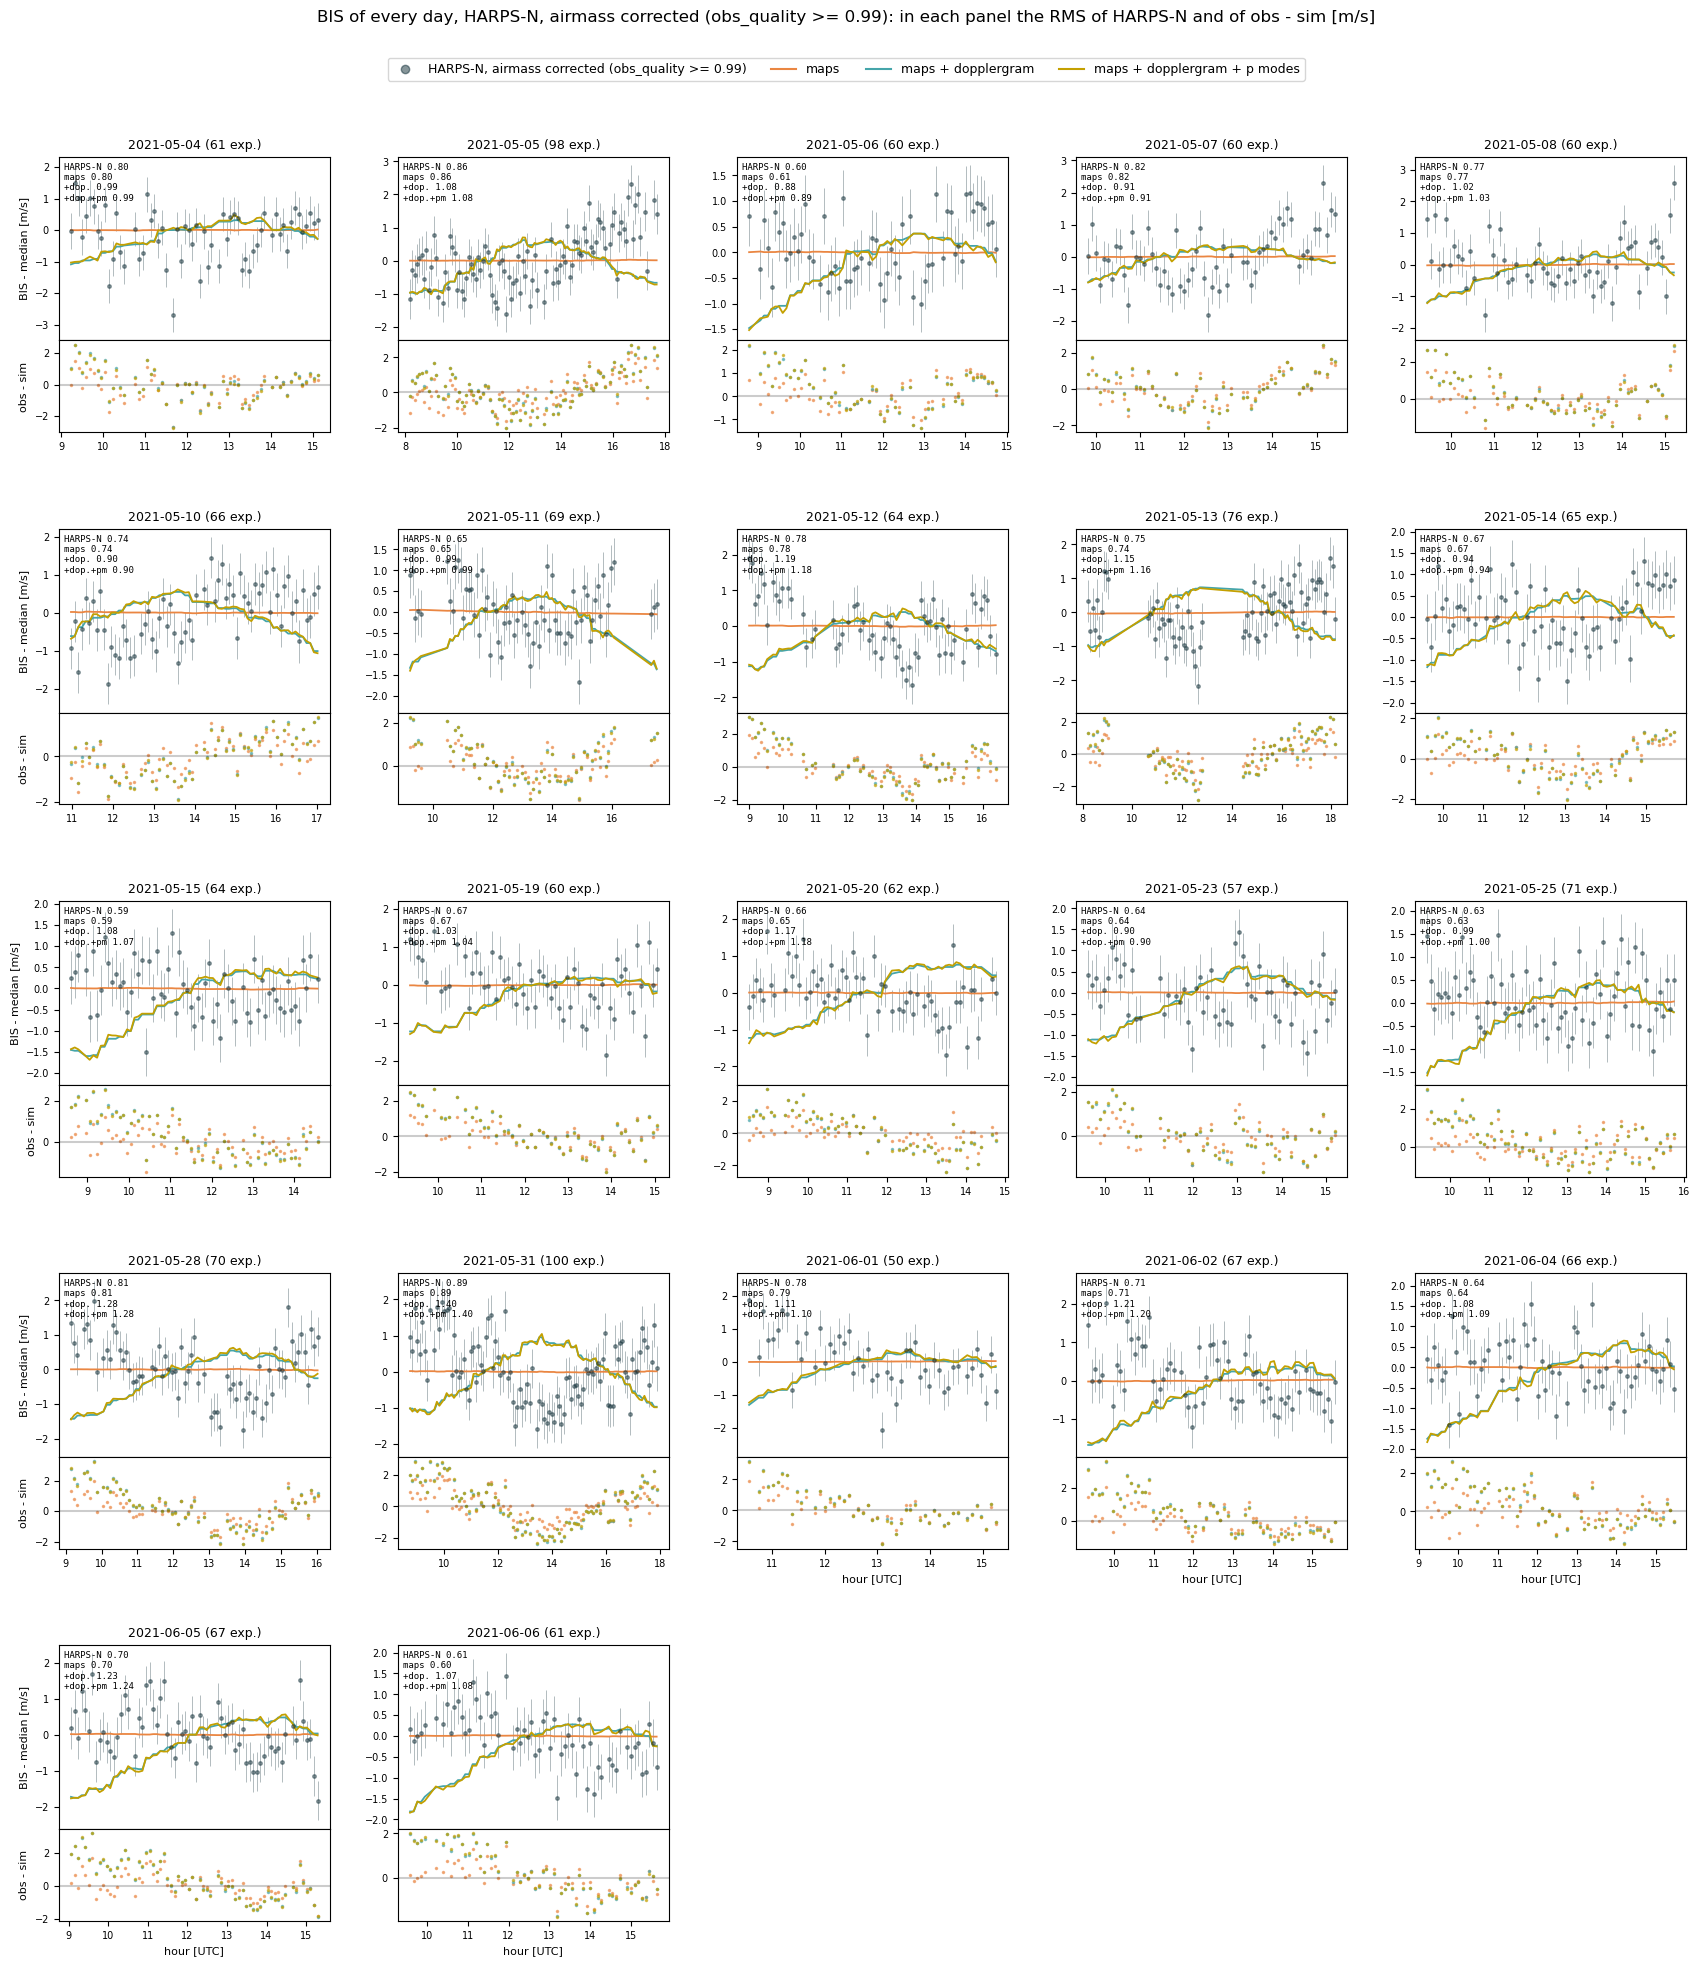

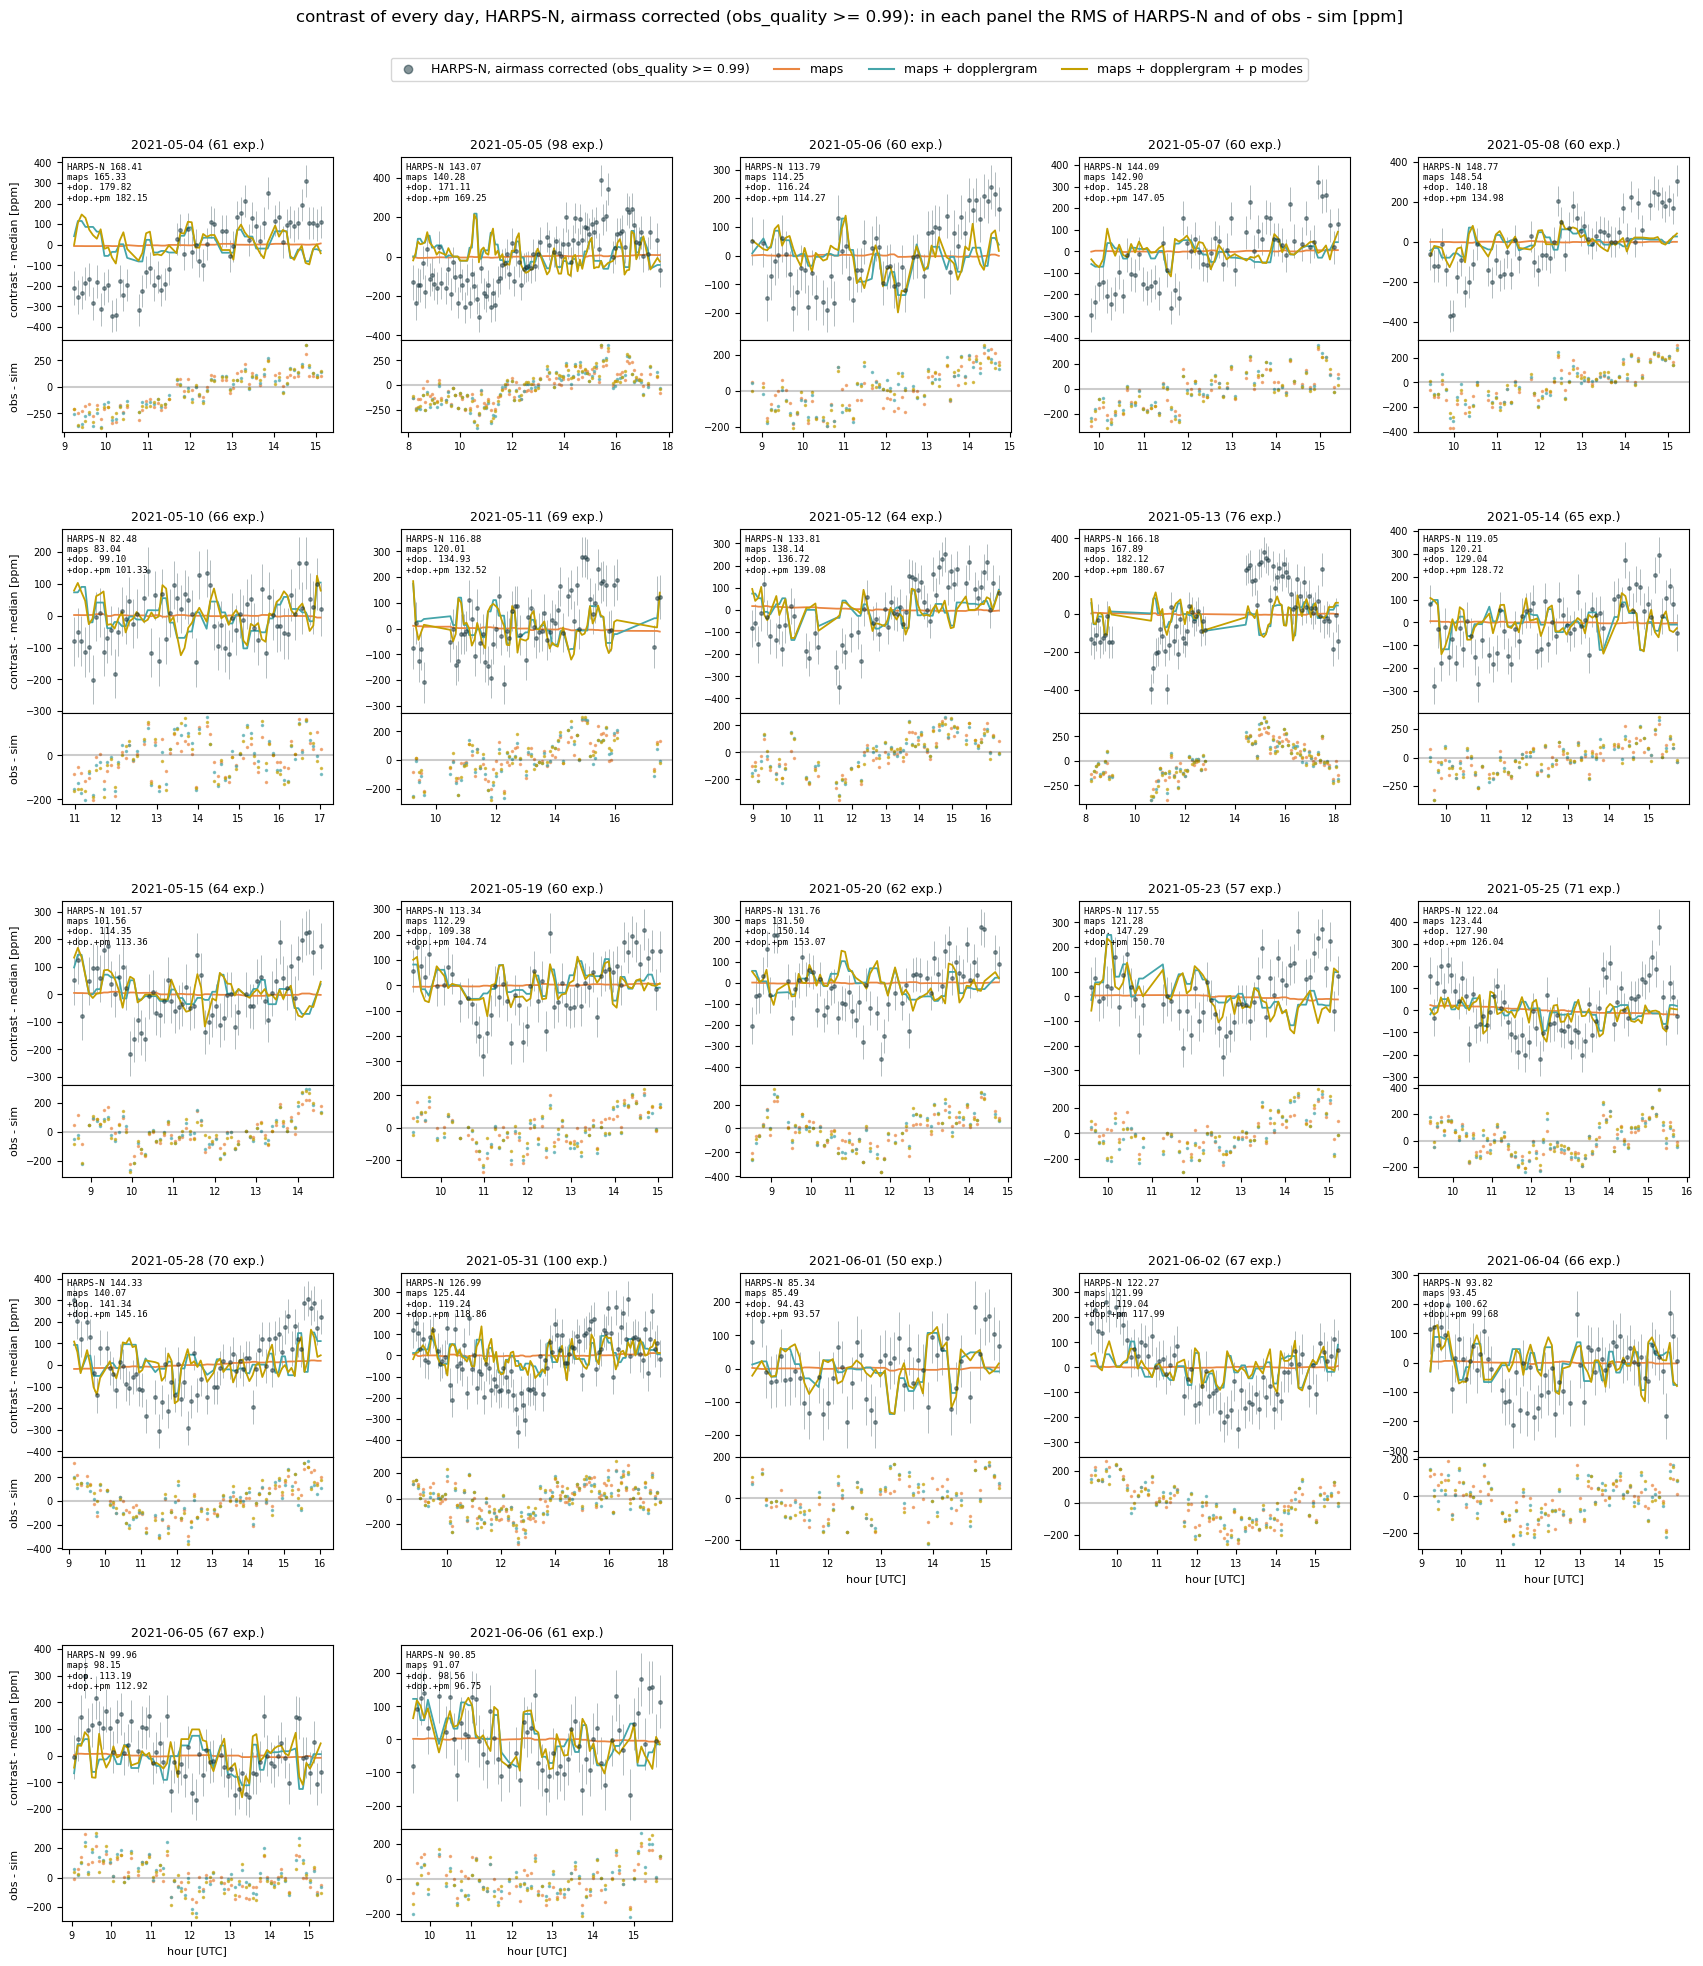

In [13]:
# the figures of section 5 again, with HARPS-N corrected for the airmass
every_day(kept, 'obs_airmass', 'HARPS-N, airmass corrected (obs_quality >= %g)' % MIN_OBS_QUALITY, 'every_day_%s_airmass.png')

## 6. Daily means: all the exposures against the exposures of good quality

The same comparison on **one value per day** (`daily_means.csv` of `collect`: the mean of the exposures of the day, days with at least `min_exp` = 5 exposures; error = std / √n), for `results_all` and `results_quality_<MIN_OBS_QUALITY>_days<MIN_DAY_EXP>`. As in `collect`: medians removed and one offset per instrumental period (`harpsn_interventions`).

The quality cut changes the daily means in two ways: it moves the mean of the days that stay (fewer exposures in the day), and it removes the days left with fewer than `MIN_DAY_EXP` exposures. The second changes the set of days, so the table below also has all the exposures **on the same days** as the run with the quality cut: the difference between the last two runs is the effect of the cut within the days only.

In [14]:
from sunsim import observations as obs
CUTS = obs.load_interventions(str(local_path('harpsn_interventions')), START)
DAILY_MODELS = (('maps', '#ea8642'), ('maps + dopplergram', '#45a5aa'))

def daily(results, days=None):
    """daily_means.csv of a run (only the days of days, if given) and the comparison of collect (medians removed, one
    offset per instrumental period)."""
    dm = table(results, 'daily_means.csv')
    if days is not None:
        dm = dm[dm['day'].isin(days)].reset_index(drop=True)
    hd = {'t': dm['t'].values}
    for q in LABEL:
        hd[q], hd[q + '_err'] = dm[q + '_obs'].values, dm[q + '_err'].values
    cmp = {q: {name: obs.compare_rv_exposures(hd, dm['%s_%s' % (q, name)].values, quantity=q, interventions=CUTS)
               for name, _ in DAILY_MODELS} for q in LABEL}
    return dm, cmp

dm_all, cmp_all = daily(ALL)
dm_q, cmp_q = daily(QUAL)
dm_same, cmp_same = daily(ALL, dm_q['day'])                     # all the exposures, on the days of QUAL only
both = dm_all.merge(dm_q, on='day', suffixes=(' all', ' quality'))
print('%d days in the daily means of all the exposures, %d with obs_quality >= %g (>= 5 exposures); left out: %s'
      % (len(dm_all), len(dm_q), MIN_OBS_QUALITY, ', '.join(sorted(set(dm_all['day']) - set(dm_q['day'])))))
print('how much the cut moves the daily means of HARPS-N (days in both runs):')
display(pd.DataFrame({q: {'RMS of (quality - all)': np.std(both[q + '_obs quality'] - both[q + '_obs all']),
                          'max |quality - all|': np.max(np.abs(both[q + '_obs quality'] - both[q + '_obs all'])),
                          'median error of the daily mean (all)': np.median(both[q + '_err all']),
                          'median error of the daily mean (quality)': np.median(both[q + '_err quality'])}
                      for q in LABEL}).round(3))

# the statistics of daily_stats.csv, also for all the exposures on the same days as QUAL
rows = []
for q in LABEL:
    for name, _ in DAILY_MODELS:
        row = {'quantity': q, 'model': name}
        for cmp, run in ((cmp_all, 'all, %d days' % len(dm_all)), (cmp_same, 'all, same %d days' % len(dm_q)),
                         (cmp_q, 'obs_quality >= %g, %d days' % (MIN_OBS_QUALITY, len(dm_q)))):
            c = cmp[q][name]
            s = c['obs'] - c['res']                                 # simulation + offsets
            row.update({(run, 'RMS obs'): c['rms_obs'], (run, 'RMS obs - sim'): c['rms'],
                        (run, 'r'): np.corrcoef(s, c['obs'])[0, 1], (run, 'slope'): np.polyfit(s, c['obs'], 1)[0]})
        rows.append(row)
daily_tab = pd.DataFrame(rows).set_index(['quantity', 'model'])
daily_tab.columns = pd.MultiIndex.from_tuples(daily_tab.columns)
daily_tab.round(3)

37 days in the daily means of all the exposures, 22 with obs_quality >= 0.99 (>= 5 exposures); left out: 2021-05-01, 2021-05-03, 2021-05-09, 2021-05-16, 2021-05-18, 2021-05-21, 2021-05-22, 2021-05-24, 2021-05-26, 2021-05-29, 2021-05-30, 2021-06-08, 2021-06-09, 2021-06-10, 2021-06-12
how much the cut moves the daily means of HARPS-N (days in both runs):


,rv,fwhm,bis,contrast
RMS of (quality - all),0.017,0.046,0.034,8.368
max |quality - all|,0.067,0.132,0.129,31.192
median error of the daily mean (all),0.059,0.150,0.088,16.642
median error of the daily mean (quality),0.061,0.150,0.088,16.651


all, 37 days                              \
                                 RMS obs RMS obs - sim      r  slope   
quantity model                                                         
rv       maps                      0.825         0.659  0.606  0.892   
         maps + dopplergram        0.825         1.069  0.352  0.282   
fwhm     maps                      0.919         0.926  0.238  0.469   
         maps + dopplergram        0.919         0.885  0.395  0.578   
bis      maps                      0.522         0.541 -0.008 -0.031   
         maps + dopplergram        0.522         0.772 -0.187 -0.203   
contrast maps                    149.218       173.211  0.029  0.047   
         maps + dopplergram      149.218       183.740  0.075  0.095   

                            all, same 22 days                              \
                                      RMS obs RMS obs - sim      r  slope   
quantity model                                                              
rv       maps                           0.783         0.525  0.747  1.123   
         maps + dopplergram             0.783         1.068  0.152  0.139   
fwhm     maps                           0.954         0.938  0.257  0.584   
         maps + dopplergram             0.954         0.874  0.428  0.737   
bis      maps                           0.462         0.496 -0.088 -0.278   
         maps + dopplergram             0.462         0.522  0.176  0.240   
contrast maps                         123.044       122.824  0.324  0.504   
         maps + dopplergram           123.044       132.036  0.356  0.403   

                            obs_quality >= 0.99, 22 days                       \
                                                 RMS obs RMS obs - sim      r   
quantity model                                                                  
rv       maps                                      0.782         0.526  0.744   
         maps + dopplergram                        0.782         1.067  0.151   
fwhm     maps                                      0.956         0.945  0.247   
         maps + dopplergram                        0.956         0.891  0.402   
bis      maps                                      0.463         0.494 -0.059   
         maps + dopplergram                        0.463         0.514  0.192   
contrast maps                                    123.535       124.704  0.304   
         maps + dopplergram                      123.535       134.387  0.334   

                                    
                             slope  
quantity model                      
rv       maps                1.116  
         maps + dopplergram  0.138  
fwhm     maps                0.561  
         maps + dopplergram  0.701  
bis      maps               -0.186  
         maps + dopplergram  0.271  
contrast maps                0.477  
         maps + dopplergram  0.381

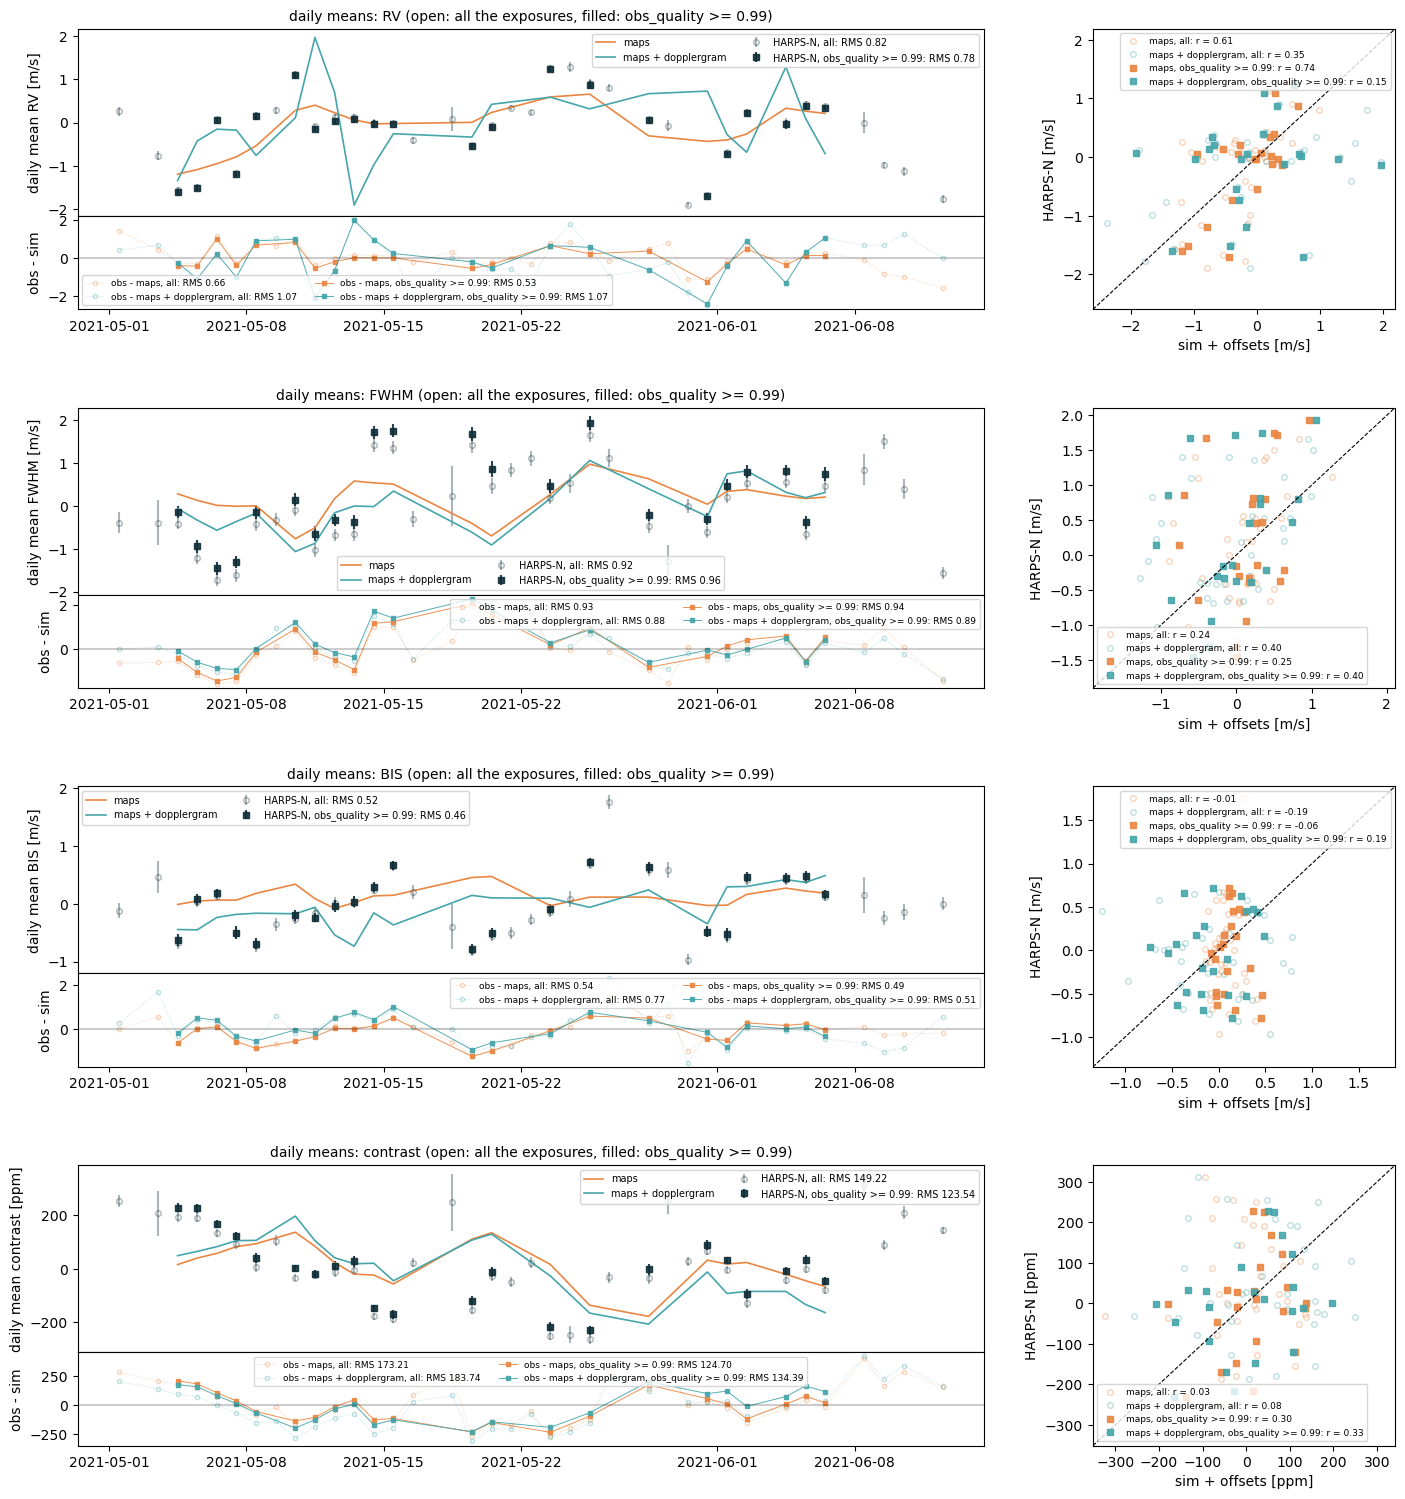

In [15]:
# daily means over the period (left) and HARPS-N against the simulations (right); open: all the exposures, filled: QUAL
fig = plt.figure(figsize=(17, 4.6 * len(LABEL)))
outer = fig.add_gridspec(len(LABEL), 2, width_ratios=[3, 1], hspace=0.35, wspace=0.18)
date = lambda t: pd.Timestamp(START) + pd.to_timedelta(t, unit='D')
runs = ((cmp_all, 'all', 'o', 0.35), (cmp_q, 'obs_quality >= %g' % MIN_OBS_QUALITY, 's', 0.9))
for k, q in enumerate(LABEL):
    inner = outer[k, 0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0)
    ax, ar = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    ar.sharex(ax)
    ac = fig.add_subplot(outer[k, 1])
    for cmp, run, mk, alpha in runs:
        filled = run != 'all'
        c0 = cmp[q][DAILY_MODELS[0][0]]
        ax.errorbar(date(c0['t']), c0['obs'], yerr=c0['obs_err'], fmt=mk, ms=4, color='#102e37', alpha=alpha,
                    mfc='#102e37' if filled else 'none', label='HARPS-N, %s: RMS %.2f' % (run, c0['rms_obs']))
        for name, col in DAILY_MODELS:
            c = cmp[q][name]
            s = c['obs'] - c['res']                                 # simulation + offsets
            if filled:
                ax.plot(date(c['t']), s, '-', color=col, lw=1.2, label=name)
            ar.plot(date(c['t']), c['res'], mk + ('-' if filled else ':'), ms=3, lw=0.7, color=col, alpha=alpha,
                    mfc=col if filled else 'none', label='obs - %s, %s: RMS %.2f' % (name, run, c['rms']))
            ac.plot(s, c['obs'], mk, ms=4, color=col, alpha=alpha, mfc=col if filled else 'none',
                    label='%s, %s: r = %.2f' % (name, run, np.corrcoef(s, c['obs'])[0, 1]))
    for cut in cmp_all[q][DAILY_MODELS[0][0]]['interventions']:     # the interventions within the period
        for a_ in (ax, ar):
            a_.axvline(date(cut), color='k', alpha=0.3)
    ar.axhline(0, color='k', alpha=0.2)
    ax.tick_params(labelbottom=False)
    ax.set_ylabel('daily mean %s [%s]' % (LABEL[q], UNIT[q])); ar.set_ylabel('obs - sim')
    ax.set_title('daily means: %s (open: all the exposures, filled: obs_quality >= %g)' % (LABEL[q], MIN_OBS_QUALITY),
                 fontsize=10)
    ax.legend(fontsize=7, ncol=2); ar.legend(fontsize=6.5, ncol=2)
    lim = np.array(ac.get_xlim() + ac.get_ylim())
    lim = [lim.min(), lim.max()]
    ac.plot(lim, lim, 'k--', lw=0.8); ac.set_xlim(lim); ac.set_ylim(lim)
    ac.set_xlabel('sim + offsets [%s]' % UNIT[q]); ac.set_ylabel('HARPS-N [%s]' % UNIT[q]); ac.legend(fontsize=6.5)
plt.savefig(os.path.join(OUT, QUAL, 'figures', 'daily_all_vs_quality.png'), dpi=130, bbox_inches='tight')
plt.show()

### 6.1 Daily means against the threshold

`daily_stats.csv` of the runs of section 4: RMS of obs − sim and r of the daily means against the threshold (0.9: all the exposures). Each threshold has its own set of days (days with fewer than `MIN_DAY_EXP` exposures left are dropped).

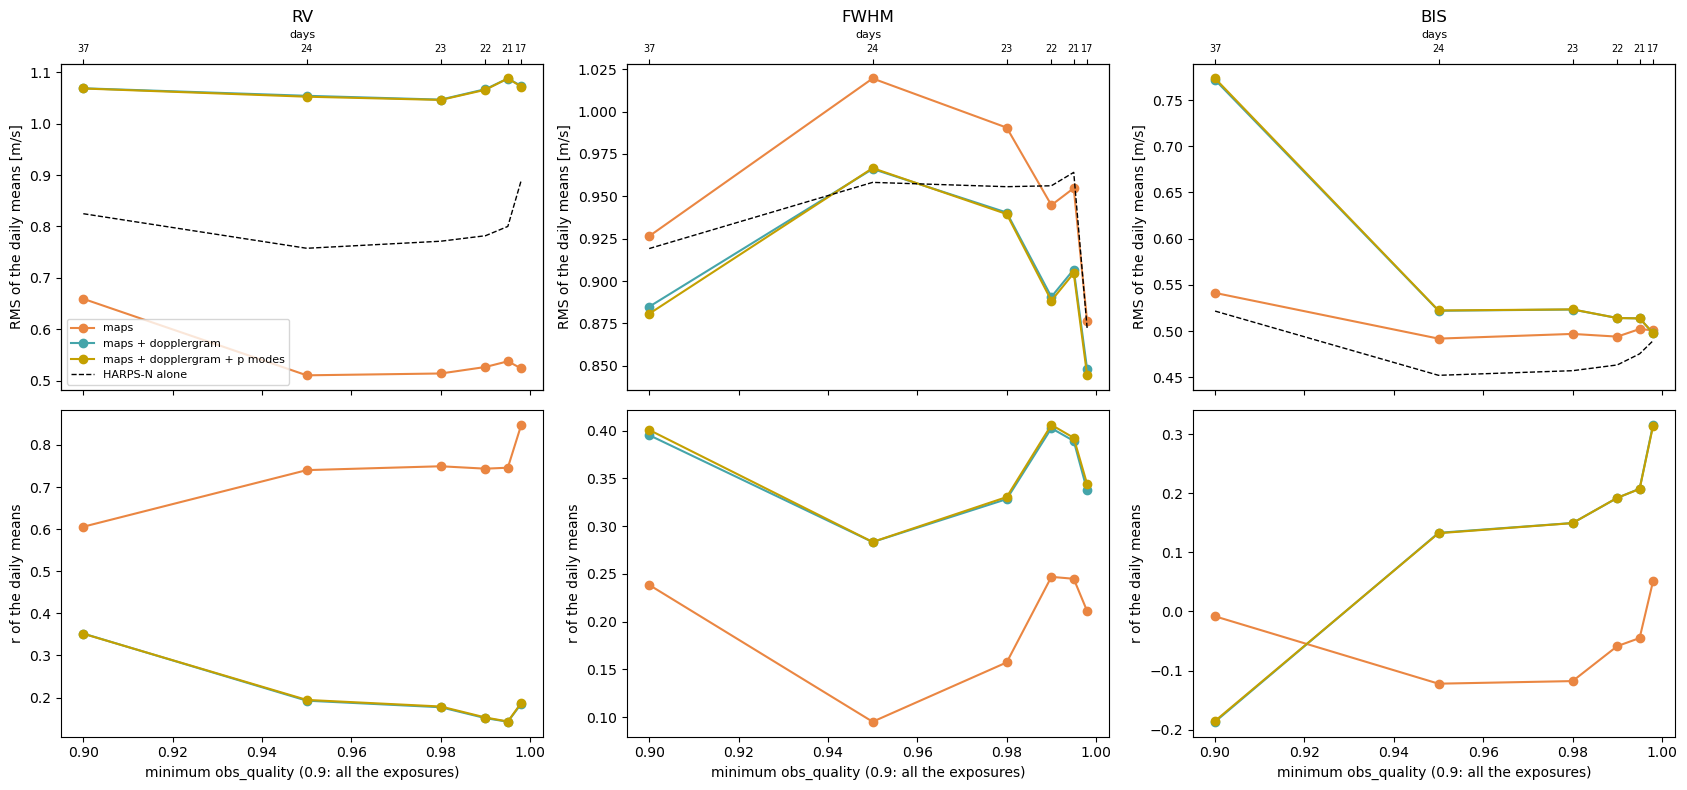

RMS obs - sim                    \
threshold                                     0.900    0.950    0.980   
quantity model                                                          
bis      maps                                 0.541    0.492    0.497   
         maps + dopplergram                   0.772    0.522    0.523   
         maps + dopplergram + p modes         0.773    0.522    0.524   
contrast maps                               173.211  120.158  122.639   
         maps + dopplergram                 183.740  128.636  131.322   
         maps + dopplergram + p modes       183.907  128.828  131.645   
fwhm     maps                                 0.926    1.020    0.991   
         maps + dopplergram                   0.885    0.966    0.940   
         maps + dopplergram + p modes         0.881    0.967    0.940   
rv       maps                                 0.659    0.510    0.514   
         maps + dopplergram                   1.069    1.054    1.047   
         maps + dopplergram + p modes         1.069    1.053    1.046   

                                                                      r  \
threshold                                0.990    0.995    0.998  0.900   
quantity model                                                            
bis      maps                            0.494    0.502    0.501 -0.008   
         maps + dopplergram              0.514    0.514    0.498 -0.187   
         maps + dopplergram + p modes    0.514    0.514    0.498 -0.185   
contrast maps                          124.704  128.103  130.394  0.029   
         maps + dopplergram            134.387  137.923  140.020  0.075   
         maps + dopplergram + p modes  134.513  138.029  139.964  0.073   
fwhm     maps                            0.945    0.955    0.876  0.238   
         maps + dopplergram              0.891    0.907    0.848  0.395   
         maps + dopplergram + p modes    0.888    0.905    0.844  0.401   
rv       maps                            0.526    0.537    0.523  0.606   
         maps + dopplergram              1.067    1.088    1.074  0.352   
         maps + dopplergram + p modes    1.066    1.088    1.072  0.352   

                                                                          
threshold                              0.950  0.980  0.990  0.995  0.998  
quantity model                                                            
bis      maps                         -0.122 -0.118 -0.059 -0.045  0.051  
         maps + dopplergram            0.133  0.150  0.192  0.208  0.316  
         maps + dopplergram + p modes  0.132  0.150  0.192  0.207  0.314  
contrast maps                          0.312  0.308  0.304  0.293  0.258  
         maps + dopplergram            0.349  0.347  0.334  0.324  0.307  
         maps + dopplergram + p modes  0.349  0.346  0.334  0.324  0.310  
fwhm     maps                          0.095  0.157  0.247  0.245  0.211  
         maps + dopplergram            0.283  0.328  0.402  0.389  0.337  
         maps + dopplergram + p modes  0.283  0.330  0.406  0.392  0.344  
rv       maps                          0.740  0.749  0.744  0.746  0.848  
         maps + dopplergram            0.193  0.177  0.151  0.143  0.185  
         maps + dopplergram + p modes  0.194  0.179  0.153  0.143  0.187

In [16]:
rows = []
for q_min in [None] + SCAN:
    name = ALL if q_min is None else ('results_scan_%g_days%d' % (q_min, MIN_DAY_EXP) if q_min != MIN_OBS_QUALITY else QUAL)
    t = table(name, 'daily_stats.csv')
    t['threshold'] = 0.9 if q_min is None else q_min
    rows.append(t)
dscan = pd.concat(rows)
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for k, q in enumerate(('rv', 'fwhm', 'bis')):
    for name, col in (('maps', '#ea8642'), ('maps + dopplergram', '#45a5aa'), ('maps + dopplergram + p modes', '#c4a000')):
        s = dscan[(dscan['quantity'] == q) & (dscan['model'] == name)].sort_values('threshold')
        axes[0, k].plot(s['threshold'], s['RMS obs - sim'], 'o-', color=col, label=name)
        axes[1, k].plot(s['threshold'], s['r'], 'o-', color=col, label=name)
    s = dscan[(dscan['quantity'] == q) & (dscan['model'] == 'maps')].sort_values('threshold')
    axes[0, k].plot(s['threshold'], s['RMS obs'], 'k--', lw=1, label='HARPS-N alone')
    axes[0, k].set_title(q.upper())
    axes[0, k].set_ylabel('RMS of the daily means [m/s]'); axes[1, k].set_ylabel('r of the daily means')
    axes[1, k].set_xlabel('minimum obs_quality (0.9: all the exposures)')
    ax2 = axes[0, k].twiny(); ax2.set_xlim(axes[0, k].get_xlim())
    ax2.set_xticks(s['threshold']); ax2.set_xticklabels(s['days'], fontsize=7); ax2.set_xlabel('days', fontsize=8)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT, QUAL, 'figures', 'threshold_scan_daily.png'), dpi=150, bbox_inches='tight')
plt.show()
dscan.pivot_table(index=['quantity', 'model'], columns='threshold', values=['RMS obs - sim', 'r']).round(3)